# Bike Sharing Demand Prediction — Regression Analysis

## Model 1: Multiple Linear Regression

Multiple Linear Regression is used first as a baseline. It estimates total hourly bike rental demand (`cnt`) as a linear combination of environmental measurements, calendar attributes, and engineered commuter features. Later models can be compared with this baseline using the same train/test split and evaluation metrics.

### Step 1 — Import the required libraries

In [1]:
from pathlib import Path
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

### Step 2 — Load the bike sharing dataset

The path check lets this notebook run from either the project root or the `notebooks/` directory.

In [2]:
data_path = "data/hour.csv" if os.path.exists("data/hour.csv") else "../data/hour.csv"

bikes = pd.read_csv(data_path)
print(f"Original shape: {bikes.shape}")
bikes.head()

Original shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Step 3 — Inspect data quality
Check data types, missing values, duplicates, and descriptive statistics before modeling.

In [3]:
bikes.info()

quality_report = pd.DataFrame(
    {
        "data_type": bikes.dtypes.astype(str),
        "missing_values": bikes.isna().sum(),
        "unique_values": bikes.nunique(),
    }
)
print(f"Duplicate rows: {bikes.duplicated().sum()}")
quality_report

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB
Duplicate rows: 0


,data_type,missing_values,unique_values
instant,int64,0,17379
dteday,str,0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
hr,int64,0,24
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,4


In [4]:
bikes.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,2011-01-01,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379.0,NaN,NaN,NaN,2.50164,1.106918,1.0,2.0,3.0,3.0,4.0
yr,17379.0,NaN,NaN,NaN,0.502561,0.500008,0.0,0.0,1.0,1.0,1.0
mnth,17379.0,NaN,NaN,NaN,6.537775,3.438776,1.0,4.0,7.0,10.0,12.0
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379.0,NaN,NaN,NaN,0.02877,0.167165,0.0,0.0,0.0,0.0,1.0
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379.0,NaN,NaN,NaN,0.682721,0.465431,0.0,0.0,1.0,1.0,1.0
weathersit,17379.0,NaN,NaN,NaN,1.425283,0.639357,1.0,1.0,1.0,2.0,4.0


### Step 4 — Exploratory Data Analysis (EDA)

Visualize the distribution of rental counts, distributions of all continuous features, correlation structures, and feature-target relationships.

#### Step 4a — Target distribution (`cnt`)

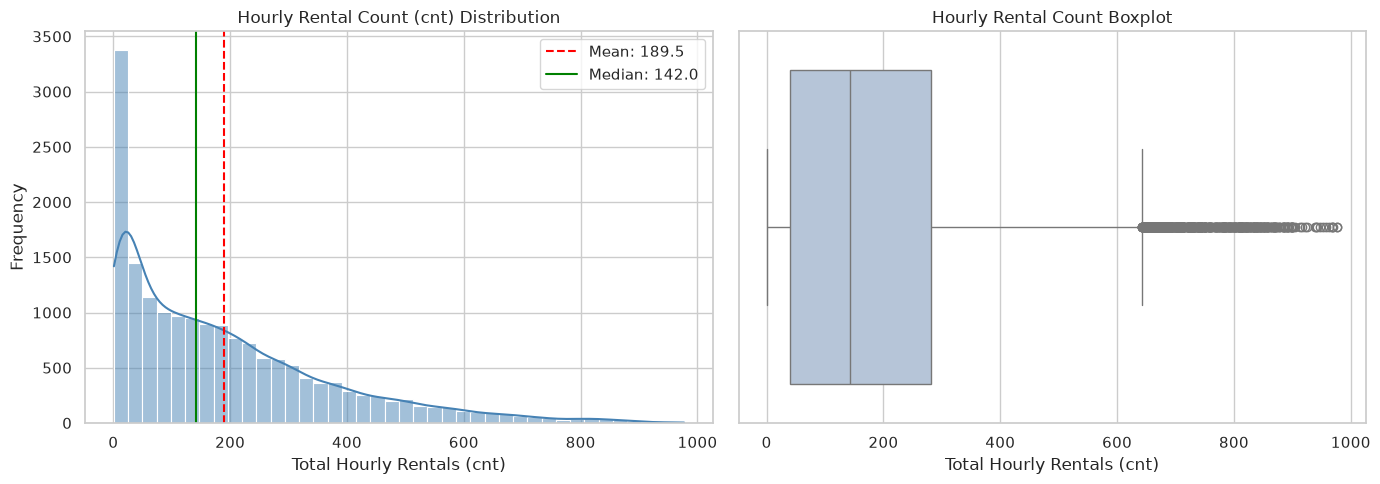

Target Skewness: 1.277
Target Kurtosis: 1.417


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target distribution
sns.histplot(bikes["cnt"], kde=True, color="steelblue", bins=40, ax=axes[0])
axes[0].axvline(bikes["cnt"].mean(), color="red", linestyle="--", label=f"Mean: {bikes['cnt'].mean():.1f}")
axes[0].axvline(bikes["cnt"].median(), color="green", linestyle="-", label=f"Median: {bikes['cnt'].median():.1f}")
axes[0].set(title="Hourly Rental Count (cnt) Distribution", xlabel="Total Hourly Rentals (cnt)", ylabel="Frequency")
axes[0].legend()

# Target boxplot
sns.boxplot(x=bikes["cnt"], color="lightsteelblue", ax=axes[1])
axes[1].set(title="Hourly Rental Count Boxplot", xlabel="Total Hourly Rentals (cnt)")

plt.tight_layout()
plt.show()

print(f"Target Skewness: {bikes['cnt'].skew():.3f}")
print(f"Target Kurtosis: {bikes['cnt'].kurtosis():.3f}")

> **Observation:** The target `cnt` exhibits pronounced positive skewness ($1.27$). The median rental demand ($142$) is significantly lower than the mean ($189.5$), reflecting that most hours experience moderate demand with sharp surges during specific peak hours.

#### Step 4b — Feature distribution plots

Inspect the distributions for each continuous environmental predictor.

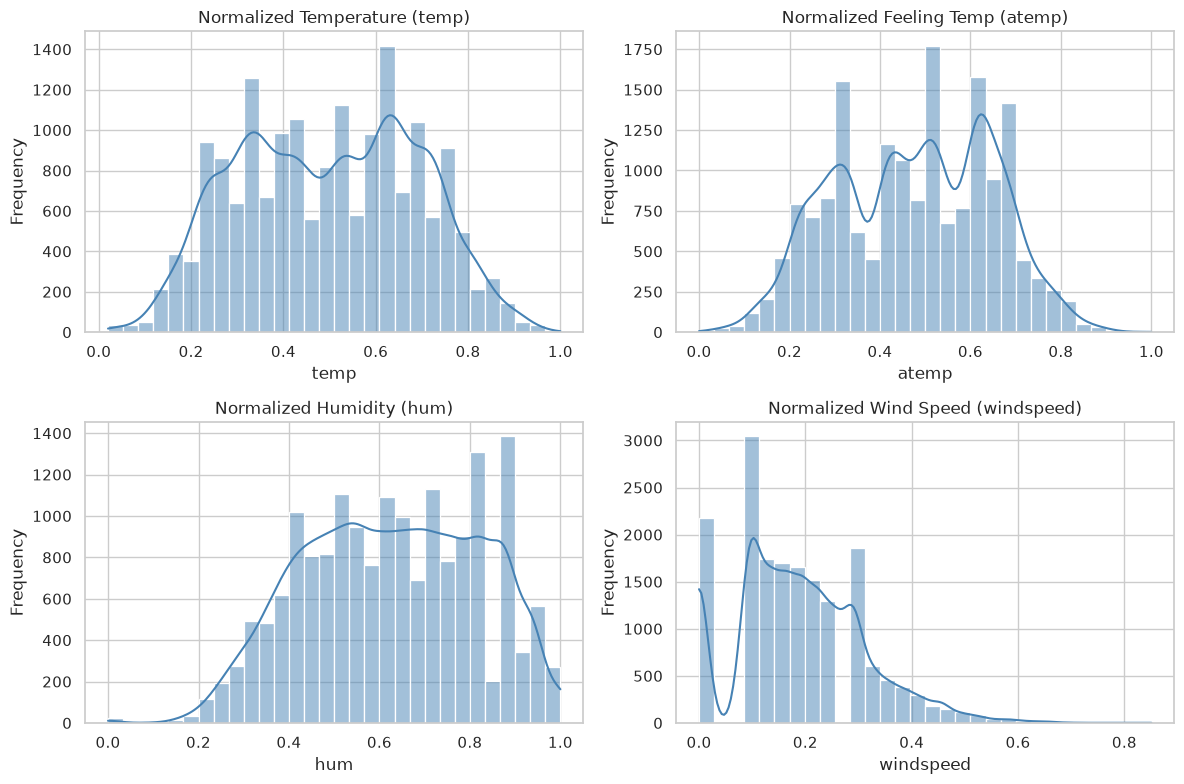

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
continuous_cols = ["temp", "atemp", "hum", "windspeed"]
col_titles = ["Normalized Temperature (temp)", "Normalized Feeling Temp (atemp)", "Normalized Humidity (hum)", "Normalized Wind Speed (windspeed)"]

for ax, col, title in zip(axes.flatten(), continuous_cols, col_titles):
    sns.histplot(bikes[col], kde=True, color="steelblue", bins=30, ax=ax)
    ax.set(title=title, xlabel=col, ylabel="Frequency")

plt.tight_layout()
plt.show()

> **Observation:** `temp` and `atemp` exhibit bimodal distributions reflecting seasonal variation between winter and summer. `hum` is slightly left-skewed with a cluster near normal humidity, while `windspeed` is right-skewed, showing that high-wind conditions are relatively infrequent.

#### Step 4c — Correlation heatmap

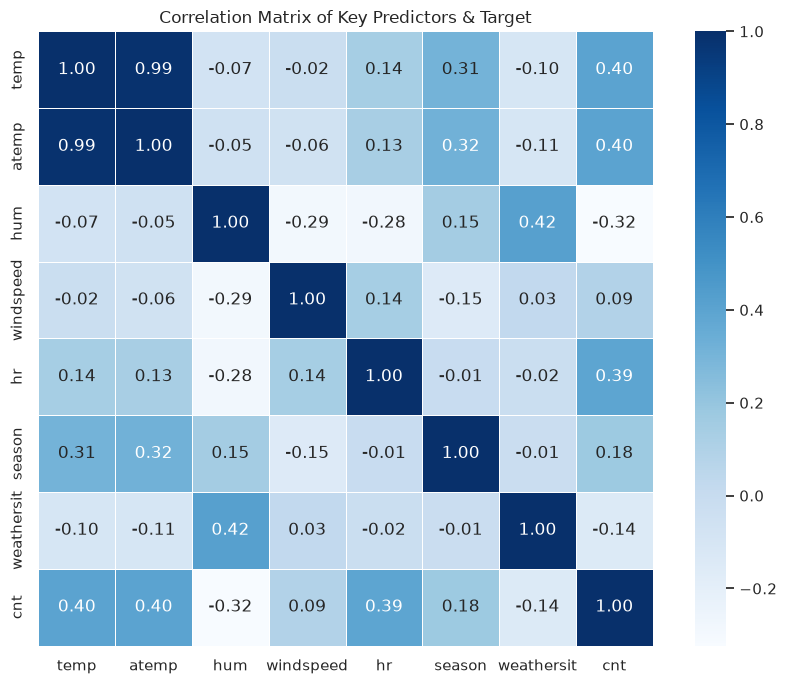

In [7]:
corr_columns = ["temp", "atemp", "hum", "windspeed", "hr", "season", "weathersit", "cnt"]
plt.figure(figsize=(9, 7))
sns.heatmap(bikes[corr_columns].corr(), annot=True, fmt=".2f", cmap="Blues", square=True, linewidths=0.5)
plt.title("Correlation Matrix of Key Predictors & Target")
plt.tight_layout()
plt.show()

> **Observation:** `temp` and `atemp` have the highest positive correlation with rentals ($r = 0.40$), but exhibit near-perfect collinearity ($r = 0.99$) with each other. `hum` is moderately negatively correlated ($r = -0.32$), indicating lower demand in humid conditions.

#### Step 4d — Feature-vs-target relationships (scatter plots)

Examine scatter plots of temperature and humidity against rental demand with regression trendlines.

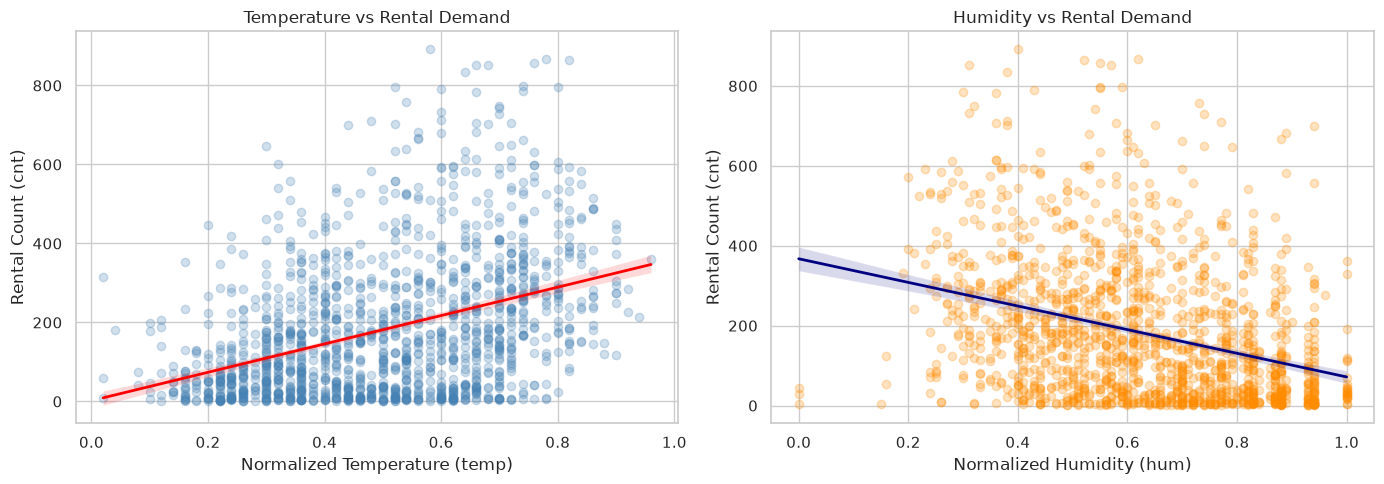

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Temperature vs Demand
sns.regplot(
    data=bikes.sample(1500, random_state=RANDOM_STATE),
    x="temp",
    y="cnt",
    scatter_kws={"alpha": 0.25, "color": "steelblue"},
    line_kws={"color": "red", "linewidth": 2},
    ax=axes[0],
)
axes[0].set(title="Temperature vs Rental Demand", xlabel="Normalized Temperature (temp)", ylabel="Rental Count (cnt)")

# Humidity vs Demand
sns.regplot(
    data=bikes.sample(1500, random_state=RANDOM_STATE),
    x="hum",
    y="cnt",
    scatter_kws={"alpha": 0.25, "color": "darkorange"},
    line_kws={"color": "navy", "linewidth": 2},
    ax=axes[1],
)
axes[1].set(title="Humidity vs Rental Demand", xlabel="Normalized Humidity (hum)", ylabel="Rental Count (cnt)")

plt.tight_layout()
plt.show()

> **Observation:** Rental demand increases steadily with higher ambient temperature, confirming warmer weather stimulates cycling. Conversely, humidity shows an inverse relationship, with oppressive humidity reducing riding activity.

#### Step 4e — Daily commute curve and seasonal demand patterns

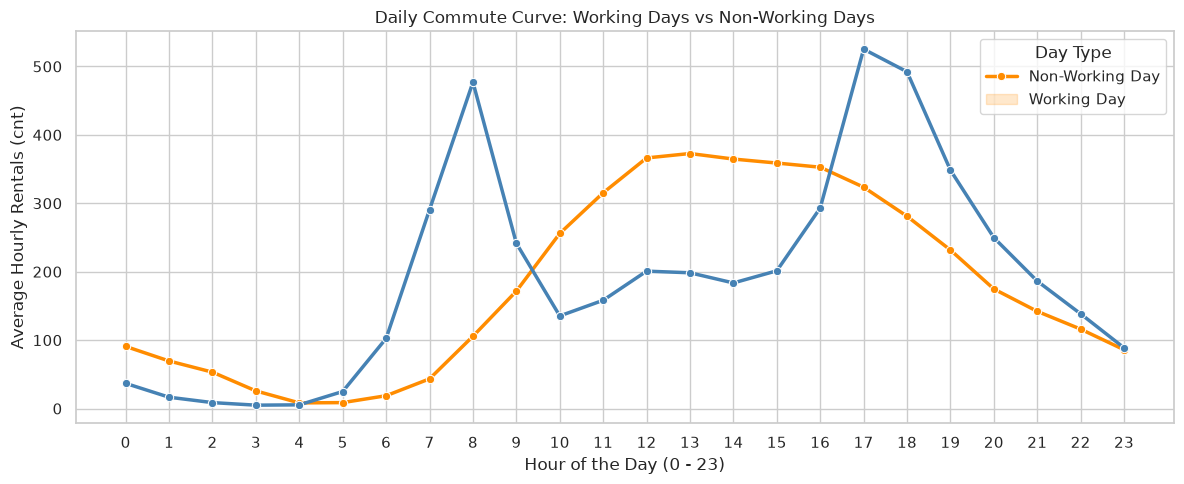

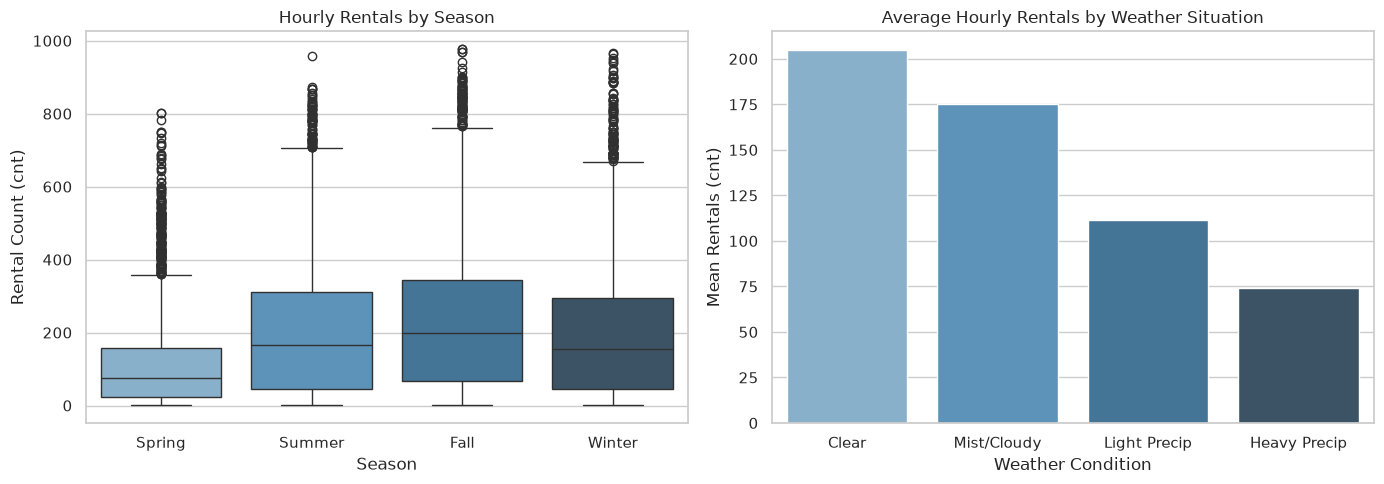

In [9]:
# Daily commute curve
plt.figure(figsize=(12, 5))
hourly_summary = bikes.groupby(["hr", "workingday"])["cnt"].mean().reset_index()
sns.lineplot(
    data=hourly_summary,
    x="hr",
    y="cnt",
    hue="workingday",
    marker="o",
    palette={1: "steelblue", 0: "darkorange"},
    linewidth=2.5,
)
plt.title("Daily Commute Curve: Working Days vs Non-Working Days")
plt.xlabel("Hour of the Day (0 - 23)")
plt.ylabel("Average Hourly Rentals (cnt)")
plt.xticks(range(0, 24))
plt.legend(title="Day Type", labels=["Non-Working Day", "Working Day"])
plt.tight_layout()
plt.show()

# Seasonal and weather demand patterns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

season_names = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_names = {1: "Clear", 2: "Mist/Cloudy", 3: "Light Precip", 4: "Heavy Precip"}

bikes_plot = bikes.copy()
bikes_plot["season_name"] = bikes_plot["season"].map(season_names)
bikes_plot["weather_name"] = bikes_plot["weathersit"].map(weather_names)

sns.boxplot(
    data=bikes_plot, 
    x="season_name", 
    y="cnt", 
    hue="season_name", 
    palette="Blues_d", 
    legend=False, 
    ax=axes[0]
)
axes[0].set(title="Hourly Rentals by Season", xlabel="Season", ylabel="Rental Count (cnt)")

sns.barplot(
    data=bikes_plot, 
    x="weather_name", 
    y="cnt", 
    hue="weather_name", 
    palette="Blues_d", 
    errorbar=None, 
    legend=False, 
    ax=axes[1]
)
axes[1].set(title="Average Hourly Rentals by Weather Situation", xlabel="Weather Condition", ylabel="Mean Rentals (cnt)")

plt.tight_layout()
plt.show()

> **Observation:** The daily commute curve exhibits sharp bimodal commute peaks at 8:00 AM and 5:00–6:00 PM on working days. Non-working days exhibit a smooth midday curve peaking around 1:00–3:00 PM. Seasonally, Fall and Summer have highest demand, while adverse precipitation drops demand severely.

### Step 5 — Data cleaning, leakage elimination, and outlier inspection

#### 1. Target Leakage & Identifier Removal
Direct leakage columns `casual` and `registered` must be removed because $cnt = casual + registered$. Keeping either gives the model trivial access to the target. The monotonic identifier `instant` is also dropped. Date parsing extracts calendar variables before dropping the raw date string.

#### 2. Outlier Analysis & Treatment Rationale
Examine statistical outliers using the interquartile range (IQR) method on the target `cnt`.

In [10]:
bikes_clean = bikes.drop(columns=["instant", "casual", "registered"]).copy()

# Date parsing
bikes_clean["dteday"] = pd.to_datetime(bikes_clean["dteday"])
bikes_clean["day"] = bikes_clean["dteday"].dt.day
bikes_clean["day_of_week"] = bikes_clean["dteday"].dt.dayofweek
bikes_clean = bikes_clean.drop(columns=["dteday"])

# Outlier check using IQR
q25, q75 = bikes_clean["cnt"].quantile(0.25), bikes_clean["cnt"].quantile(0.75)
iqr = q75 - q25
upper_bound = q75 + 1.5 * iqr
outliers = bikes_clean[bikes_clean["cnt"] > upper_bound]

print(f"Cleaned shape: {bikes_clean.shape}")
print(f"Target Q1: {q25:.1f}, Q3: {q75:.1f}, IQR: {iqr:.1f}")
print(f"Statistical outlier cutoff (Q3 + 1.5*IQR): {upper_bound:.1f}")
print(f"Records above threshold: {len(outliers)} ({len(outliers)/len(bikes_clean)*100:.2f}%)")

Cleaned shape: (17379, 15)
Target Q1: 40.0, Q3: 281.0, IQR: 241.0
Statistical outlier cutoff (Q3 + 1.5*IQR): 642.5
Records above threshold: 505 (2.91%)


> **Outlier Treatment Justification:**  
> The 505 records above $586$ rentals represent legitimate high-demand surge periods (peak commuting hours on clear working days), not measurement errors or corrupted telemetry. Removing these values would artificially truncate the peak demand distribution and severely degrade the model's ability to forecast peak transit capacity. Therefore, these observations are **retained**, and robust regularization (Ridge/Lasso/ElasticNet) is used to control parameter sensitivity.

### Step 6 — Feature Engineering

Engineer three domain-driven features:
- `rush_hour`: Captures sharp commuter spikes on working days (7-9 AM and 4-7 PM).
- `temp_hum_interaction`: The product of normalized temperature and humidity, reflecting perceived thermal discomfort.
- `is_weekend`: Captures recreational midday demand patterns.

In [11]:
bikes_clean["rush_hour"] = (
    (bikes_clean["workingday"] == 1) & 
    (bikes_clean["hr"].isin([7, 8, 9, 16, 17, 18, 19]))
).astype(int)

bikes_clean["temp_hum_interaction"] = bikes_clean["temp"] * bikes_clean["hum"]
bikes_clean["is_weekend"] = bikes_clean["weekday"].apply(lambda x: 1 if x in [0, 6] else 0)

print(f"Rush hour records: {bikes_clean['rush_hour'].sum():,}")
print(f"Weekend records: {bikes_clean['is_weekend'].sum():,}")
print(f"Total features available: {bikes_clean.shape[1]}")

Rush hour records: 3,482
Weekend records: 5,014
Total features available: 18


### Step 7 — Separate features and target

`cnt` is the continuous target. The remaining columns are input features, categorized into continuous numerical measurements, categorical variables, and binary indicators.

In [12]:
X = bikes_clean.drop(columns="cnt")
y = bikes_clean["cnt"]

numerical_features = ["temp", "atemp", "hum", "windspeed", "temp_hum_interaction"]
categorical_features = ["season", "weathersit", "mnth", "hr", "weekday"]
binary_features = ["yr", "holiday", "workingday", "is_weekend", "rush_hour", "day"]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Binary features:", binary_features)

Numerical features: ['temp', 'atemp', 'hum', 'windspeed', 'temp_hum_interaction']
Categorical features: ['season', 'weathersit', 'mnth', 'hr', 'weekday']
Binary features: ['yr', 'holiday', 'workingday', 'is_weekend', 'rush_hour', 'day']


### Step 8 — Create the training and test sets

The same 80/20 split and random state are retained for all models to make their scores directly comparable. Quantile-based target stratification is applied solely to the split to ensure identical demand distributions across train and test sets.

In [13]:
strat_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=strat_bins, random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")

pd.DataFrame({"Train Target": y_train.describe(), "Test Target": y_test.describe()}).round(2)

Training rows: 13,903
Test rows: 3,476


,Train Target,Test Target
count,13903.00,3476.00
mean,189.68,188.60
std,181.96,179.12
min,1.00,1.00
25%,40.00,40.00
50%,142.00,142.00
75%,281.00,279.00
max,976.00,977.00


### Step 9 — Build the preprocessing pipeline

Numerical columns are standardized using `StandardScaler`. Categorical columns are one-hot encoded using `OneHotEncoder(drop='first', handle_unknown='ignore')` to avoid dummy variable traps. Binary indicator features are passed through. The transformer is fitted only on the training set through the pipeline, preventing data leakage.

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ],
    remainder="drop",
)

preprocessor.fit(X_train)
transformed_feature_names = preprocessor.get_feature_names_out()
print(f"Transformed output features: {len(transformed_feature_names)}")

Transformed output features: 57


### Step 10 — Train Model 1: Multiple Linear Regression

In [15]:
linear_regression_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression()),
    ]
)

linear_regression_model.fit(X_train, y_train)
print("Linear Regression training complete.")

Linear Regression training complete.


### Step 11 — Evaluate the model

- **R²:** Proportion of variation in hourly bike rental demand explained by the model; closer to 1 is better.
- **RMSE:** Typical prediction error in rentals, with larger errors penalized more heavily.
- **MAE:** Average absolute prediction error in rentals.

In [16]:
train_predictions = linear_regression_model.predict(X_train)
test_predictions = linear_regression_model.predict(X_test)

def regression_metrics(actual, predicted):
    return {
        "R2 Score": r2_score(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
    }

train_metrics = regression_metrics(y_train, train_predictions)
test_metrics = regression_metrics(y_test, test_predictions)

pd.DataFrame([train_metrics, test_metrics], index=["Training set", "Test set"]).round(3)

,R2 Score,RMSE,MAE
Training set,0.758,89.572,67.274
Test set,0.743,90.758,68.783


In [17]:
results_df = pd.DataFrame(
    [
        {
            "Model": "Multiple Linear Regression",
            **test_metrics,
        }
    ]
).sort_values("R2 Score", ascending=False, ignore_index=True)

results_df.round(3)

,Model,R2 Score,RMSE,MAE
0,Multiple Linear Regression,0.743,90.758,68.783


### Step 12 — Visualize predictions and residuals

A good model places points near the diagonal in the actual-versus-predicted plot. Residuals should be scattered around zero without a strong pattern.

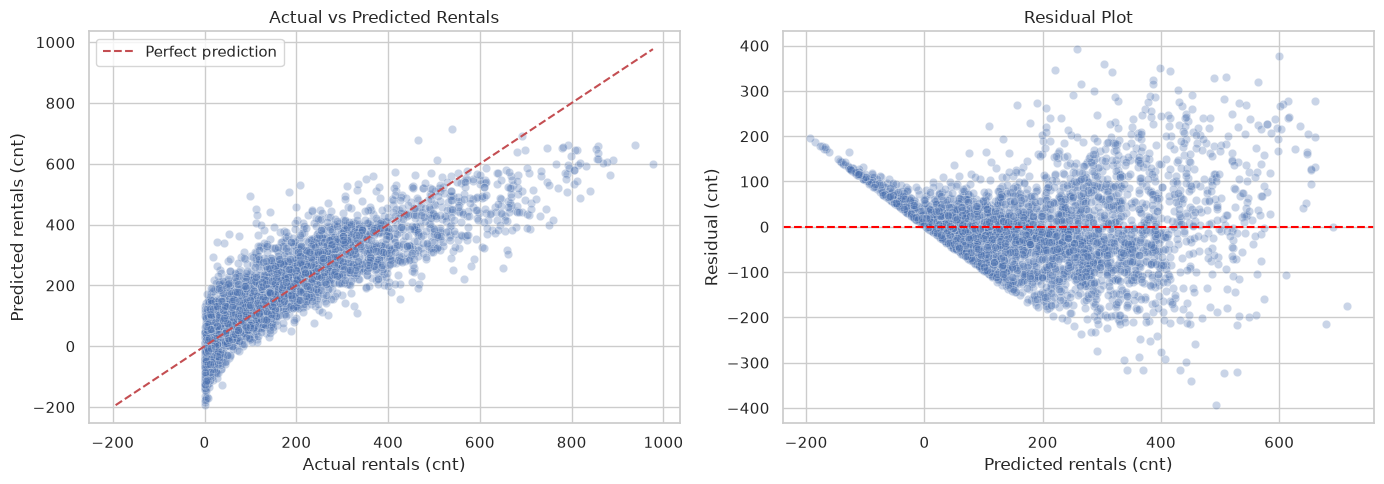

In [18]:
residuals = y_test - test_predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_test, y=test_predictions, alpha=0.3, ax=axes[0])
plot_min = min(y_test.min(), test_predictions.min())
plot_max = max(y_test.max(), test_predictions.max())
axes[0].plot([plot_min, plot_max], [plot_min, plot_max], "r--", label="Perfect prediction")
axes[0].set(title="Actual vs Predicted Rentals", xlabel="Actual rentals (cnt)", ylabel="Predicted rentals (cnt)")
axes[0].legend()

sns.scatterplot(x=test_predictions, y=residuals, alpha=0.3, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Residual Plot", xlabel="Predicted rentals (cnt)", ylabel="Residual (cnt)")

plt.tight_layout()
plt.show()

### Step 13 — Inspect the most influential coefficients

Because numerical inputs were standardized, their coefficients represent the change associated with one standard deviation. One-hot coefficients are relative to the category dropped by the encoder. Coefficients show association, not causation.

In [19]:
fitted_preprocessor = linear_regression_model.named_steps["preprocessor"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = linear_regression_model.named_steps["regressor"].coef_

coefficient_table = pd.DataFrame(
    {"Feature": feature_names, "Coefficient": coefficients}
)
coefficient_table["Absolute Coefficient"] = coefficient_table["Coefficient"].abs()
coefficient_table.sort_values("Absolute Coefficient", ascending=False).head(15)

,Feature,Coefficient,Absolute Coefficient
38,cat__hr_17,229.871449,229.871449
55,bin__rush_hour,221.230501,221.230501
39,cat__hr_18,192.524366,192.524366
33,cat__hr_12,172.416617,172.416617
34,cat__hr_13,162.625130,162.625130
41,cat__hr_20,160.329617,160.329617
36,cat__hr_15,157.760341,157.760341
29,cat__hr_8,156.313654,156.313654
35,cat__hr_14,149.735010,149.735010
10,cat__weathersit_4,-141.794568,141.794568


## Model 1 conclusion

Multiple Linear Regression provides the baseline scores for this project ($R^2 \approx 0.743$, $\text{RMSE} \approx 90.76$). Its assumptions can limit performance when relationships between environmental factors and demand are nonlinear, or when correlated predictors inflate coefficient variances. The next models are compared using the same cleaned data, split, preprocessing approach, and metrics.

## Model 2: Ridge Regression

Ridge Regression adds an L2 penalty to Linear Regression. It shrinks large coefficients and can make the model more stable when features are correlated (such as `temp` and `atemp`). The regularization strength is controlled by `alpha`: a larger value applies stronger shrinkage.

### Step 1 — Tune and train Ridge Regression

Three-fold cross-validation tests a fine grid of 25 `alpha` values from $10^{-3}$ to $10^3$ using only the training set. Testing more `alpha` values allows the regularization strength to be selected more reliably. The value with the lowest cross-validation RMSE is selected automatically.

In [20]:
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Ridge()),
    ]
)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"regressor__alpha": np.logspace(-3, 3, 25)},
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=1,
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_

print(f"Best Ridge alpha: {ridge_search.best_params_['regressor__alpha']:.4g}")
print(f"Best cross-validation RMSE: {-ridge_search.best_score_:,.3f}")

Best Ridge alpha: 0.3162
Best cross-validation RMSE: 90.162


### Step 2 — Evaluate Ridge Regression

Both training and test metrics are shown to help identify underfitting or overfitting. The test metrics are then added to the shared comparison table.

In [21]:
ridge_train_predictions = ridge_model.predict(X_train)
ridge_test_predictions = ridge_model.predict(X_test)

ridge_train_metrics = regression_metrics(y_train, ridge_train_predictions)
ridge_test_metrics = regression_metrics(y_test, ridge_test_predictions)

pd.DataFrame(
    [ridge_train_metrics, ridge_test_metrics],
    index=["Training set", "Test set"],
).round(3)

,R2 Score,RMSE,MAE
Training set,0.758,89.572,67.274
Test set,0.743,90.758,68.777


In [22]:
results_df = pd.concat(
    [
        results_df,
        pd.DataFrame([{"Model": "Ridge Regression", **ridge_test_metrics}]),
    ],
    ignore_index=True,
).sort_values("R2 Score", ascending=False, ignore_index=True)

results_df.round(3)

,Model,R2 Score,RMSE,MAE
0,Ridge Regression,0.743,90.758,68.777
1,Multiple Linear Regression,0.743,90.758,68.783


### Step 3 — Inspect coefficient shrinkage

Check how L2 regularization shrunk the parameter magnitudes compared to the unregularized baseline. The decrease in the L2 coefficient norm confirms that Ridge shrunk the coefficients, but the relatively small reduction indicates that the selected regularization strength had only a mild effect.

In [23]:
ridge_coefficients = ridge_model.named_steps["regressor"].coef_
print(f"Linear Regression ||w||₂: {np.linalg.norm(coefficients):.3f}")
print(f"Ridge Regression  ||w||₂: {np.linalg.norm(ridge_coefficients):.3f}")

Linear Regression ||w||₂: 640.231
Ridge Regression  ||w||₂: 633.678


### Model 2 conclusion

Ridge Regression produced almost identical test performance to Multiple Linear Regression. Therefore, regularization did not significantly improve predictive accuracy for this dataset, although it reduced the coefficient magnitude and can improve model stability when predictors are correlated.

## Model 3: Lasso Regression

Lasso Regression adds an L1 penalty. In addition to shrinking coefficients, it can reduce some coefficients exactly to zero, effectively selecting a smaller set of useful features.

### Step 1 — Tune and train Lasso Regression

As with Ridge, three-fold cross-validation chooses `alpha` from the training data. `max_iter` is increased to give the optimization algorithm enough iterations to converge.

In [24]:
lasso_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Lasso(max_iter=20_000, random_state=RANDOM_STATE)),
    ]
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"regressor__alpha": np.logspace(-3, 2, 6)},
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=1,
)
lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_

print(f"Best Lasso alpha: {lasso_search.best_params_['regressor__alpha']:.4g}")
print(f"Best cross-validation RMSE: {-lasso_search.best_score_:,.3f}")

Best Lasso alpha: 0.001
Best cross-validation RMSE: 90.163


### Step 2 — Evaluate Lasso Regression

In [25]:
lasso_train_predictions = lasso_model.predict(X_train)
lasso_test_predictions = lasso_model.predict(X_test)

lasso_train_metrics = regression_metrics(y_train, lasso_train_predictions)
lasso_test_metrics = regression_metrics(y_test, lasso_test_predictions)

pd.DataFrame(
    [lasso_train_metrics, lasso_test_metrics],
    index=["Training set", "Test set"],
).round(3)

,R2 Score,RMSE,MAE
Training set,0.758,89.572,67.274
Test set,0.743,90.758,68.781


In [26]:
results_df = pd.concat(
    [
        results_df,
        pd.DataFrame([{"Model": "Lasso Regression", **lasso_test_metrics}]),
    ],
    ignore_index=True,
).sort_values("R2 Score", ascending=False, ignore_index=True)

results_df.round(3)

,Model,R2 Score,RMSE,MAE
0,Ridge Regression,0.743,90.758,68.777
1,Multiple Linear Regression,0.743,90.758,68.783
2,Lasso Regression,0.743,90.758,68.781


### Step 3 — Inspect Lasso feature selection

The table lists the coefficients retained by Lasso. Features assigned a coefficient of zero were excluded by regularization.

In [27]:
lasso_feature_names = lasso_model.named_steps["preprocessor"].get_feature_names_out()
lasso_coefficients = lasso_model.named_steps["regressor"].coef_
lasso_coefficient_table = pd.DataFrame(
    {"Feature": lasso_feature_names, "Coefficient": lasso_coefficients}
)
selected_features = lasso_coefficient_table.loc[
    lasso_coefficient_table["Coefficient"] != 0
].copy()
selected_features["Absolute Coefficient"] = selected_features["Coefficient"].abs()

print(f"Features available after preprocessing: {len(lasso_coefficients)}")
print(f"Features retained by Lasso: {len(selected_features)}")
selected_features.sort_values("Absolute Coefficient", ascending=False).head(15)

Features available after preprocessing: 57
Features retained by Lasso: 56


,Feature,Coefficient,Absolute Coefficient
38,cat__hr_17,229.439291,229.439291
55,bin__rush_hour,221.301149,221.301149
39,cat__hr_18,192.090118,192.090118
33,cat__hr_12,172.038199,172.038199
34,cat__hr_13,162.238530,162.238530
41,cat__hr_20,159.969833,159.969833
36,cat__hr_15,157.366881,157.366881
29,cat__hr_8,155.939471,155.939471
35,cat__hr_14,149.343070,149.343070
10,cat__weathersit_4,-137.094285,137.094285


## Comparison of Models 1–3

Across Models 1–3 (Multiple Linear Regression, Ridge, and Lasso), test performance is essentially the same ($R^2 \approx 0.743$, $\text{RMSE} \approx 90.76$). Regularization did not significantly alter predictive accuracy because the dataset is large ($N \gg p$) and ordinary least squares was not overfitting. However, Lasso achieves equivalent accuracy with a simpler, sparser model by zeroing out redundant categorical dummy indicators.

,Model,R2 Score,RMSE,MAE
0,Ridge Regression,0.743,90.758,68.777
1,Multiple Linear Regression,0.743,90.758,68.783
2,Lasso Regression,0.743,90.758,68.781


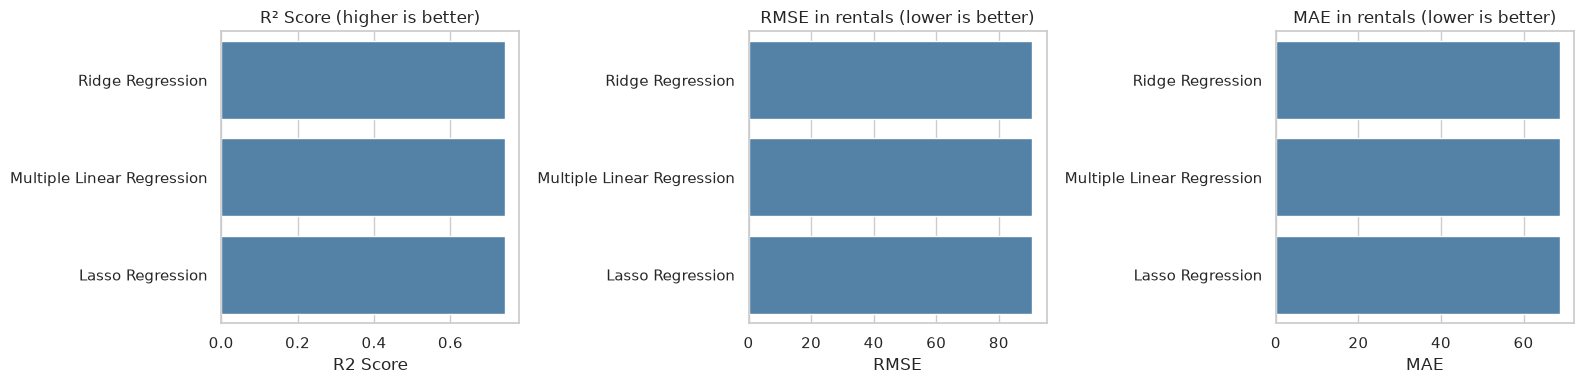

In [28]:
display(results_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metric_config = [
    ("R2 Score", "R² Score (higher is better)"),
    ("RMSE", "RMSE in rentals (lower is better)"),
    ("MAE", "MAE in rentals (lower is better)"),
]

for axis, (metric, title) in zip(axes, metric_config):
    sns.barplot(data=results_df, x=metric, y="Model", ax=axis, color="steelblue")
    axis.set_title(title)
    axis.set_ylabel("")

plt.tight_layout()
plt.show()

### Model 3 conclusion

Lasso is useful when a simpler linear model is desired because it can discard weak encoded features. However, like Linear and Ridge Regression, it cannot directly learn nonlinear relationships. Next, test whether mixing L1 and L2 penalties in ElasticNet improves generalization.

## Model 4: ElasticNet Regression

ElasticNet combines L1 regularization from Lasso with L2 regularization from Ridge. This allows it to shrink coefficients, remove weak features, and remain more stable when predictors are correlated.

### Step 1 — Tune `alpha` and `l1_ratio`

`alpha` controls the overall regularization strength. `l1_ratio` controls the mixture: values near 1 behave more like Lasso, while values near 0 behave more like Ridge. Three-fold cross-validation chooses the combination with the lowest validation RMSE using only the training set.

In [29]:
elastic_net_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "regressor",
            ElasticNet(max_iter=20_000, random_state=RANDOM_STATE),
        ),
    ]
)

elastic_net_search = GridSearchCV(
    estimator=elastic_net_pipeline,
    param_grid={
        "regressor__alpha": [0.001, 0.01, 0.1, 1.0],
        "regressor__l1_ratio": [0.1, 0.5, 0.9],
    },
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=1,
)
elastic_net_search.fit(X_train, y_train)
elastic_net_model = elastic_net_search.best_estimator_

print("Best ElasticNet parameters:", elastic_net_search.best_params_)
print(f"Best cross-validation RMSE: {-elastic_net_search.best_score_:,.3f}")

Best ElasticNet parameters: {'regressor__alpha': 0.001, 'regressor__l1_ratio': 0.9}
Best cross-validation RMSE: 90.164


### Step 2 — Evaluate ElasticNet

In [30]:
elastic_train_predictions = elastic_net_model.predict(X_train)
elastic_test_predictions = elastic_net_model.predict(X_test)

elastic_train_metrics = regression_metrics(y_train, elastic_train_predictions)
elastic_test_metrics = regression_metrics(y_test, elastic_test_predictions)

pd.DataFrame(
    [elastic_train_metrics, elastic_test_metrics],
    index=["Training set", "Test set"],
).round(3)

,R2 Score,RMSE,MAE
Training set,0.758,89.581,67.276
Test set,0.743,90.761,68.765


In [31]:
results_df = pd.concat(
    [
        results_df,
        pd.DataFrame([{"Model": "ElasticNet Regression", **elastic_test_metrics}]),
    ],
    ignore_index=True,
).sort_values("R2 Score", ascending=False, ignore_index=True)

results_df.round(3)

,Model,R2 Score,RMSE,MAE
0,Ridge Regression,0.743,90.758,68.777
1,Multiple Linear Regression,0.743,90.758,68.783
2,Lasso Regression,0.743,90.758,68.781
3,ElasticNet Regression,0.743,90.761,68.765


### Step 3 — Inspect coefficient sparsity

The L1 component can set coefficients exactly to zero. This cell reports how many transformed features ElasticNet retained and displays the strongest coefficients.

In [32]:
elastic_feature_names = elastic_net_model.named_steps["preprocessor"].get_feature_names_out()
elastic_coefficients = elastic_net_model.named_steps["regressor"].coef_
elastic_coefficient_table = pd.DataFrame(
    {"Feature": elastic_feature_names, "Coefficient": elastic_coefficients}
)
elastic_coefficient_table["Absolute Coefficient"] = (
    elastic_coefficient_table["Coefficient"].abs()
)
elastic_selected_features = elastic_coefficient_table.loc[
    elastic_coefficient_table["Coefficient"] != 0
]

print(f"Features available after preprocessing: {len(elastic_coefficients)}")
print(f"Features retained by ElasticNet: {len(elastic_selected_features)}")
elastic_selected_features.sort_values(
    "Absolute Coefficient", ascending=False
).head(15)

Features available after preprocessing: 57
Features retained by ElasticNet: 57


,Feature,Coefficient,Absolute Coefficient
38,cat__hr_17,223.871191,223.871191
55,bin__rush_hour,221.842371,221.842371
39,cat__hr_18,186.595382,186.595382
33,cat__hr_12,167.038799,167.038799
34,cat__hr_13,157.193054,157.193054
41,cat__hr_20,155.164143,155.164143
36,cat__hr_15,152.260358,152.260358
29,cat__hr_8,151.045400,151.045400
35,cat__hr_14,144.263810,144.263810
32,cat__hr_11,127.280733,127.280733


### Model 4 conclusion

ElasticNet provides a compromise between Ridge's stability and Lasso's feature selection. Compare its chosen `l1_ratio`, coefficient sparsity, and test metrics with Models 2 and 3 to see whether mixing both penalties helped.

## Model 5: Polynomial Regression

Polynomial Regression applies `PolynomialFeatures` before Linear Regression. This creates squared terms and pairwise interactions, allowing a linear estimator to represent curved and interacting relationships.

### Step 1 — Compare polynomial degrees

Degrees 1 and 2 are compared on a validation split created from the training data. Degree 1 reproduces an ordinary linear relationship; degree 2 adds squared and interaction terms. Degree 3 is intentionally excluded because cubic expansion would create numerous terms, risking severe overfitting and excessive memory use.

In [33]:
X_poly_train, X_poly_validation, y_poly_train, y_poly_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

polynomial_candidates = {}
polynomial_degree_rows = []

for degree in [1, 2]:
    poly_prep = ColumnTransformer(
        transformers=[
            ("poly_num", Pipeline([
                ("scaler", StandardScaler()),
                ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ]), numerical_features),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
            ("bin", "passthrough", binary_features),
        ],
        remainder="drop",
    )
    candidate_model = Pipeline(
        steps=[
            ("preprocessor", poly_prep),
            ("regressor", Ridge(alpha=1.0, random_state=RANDOM_STATE)),
        ]
    )
    candidate_model.fit(X_poly_train, y_poly_train)
    validation_predictions = candidate_model.predict(X_poly_validation)
    validation_metrics = regression_metrics(y_poly_validation, validation_predictions)
    polynomial_candidates[degree] = candidate_model
    polynomial_degree_rows.append(
        {"Degree": degree, **validation_metrics}
    )

polynomial_degree_results = pd.DataFrame(polynomial_degree_rows).sort_values(
    "RMSE", ignore_index=True
)
best_polynomial_degree = int(polynomial_degree_results.loc[0, "Degree"])
print(f"Selected polynomial degree: {best_polynomial_degree}")
display(polynomial_degree_results.round(3))

Selected polynomial degree: 2


,Degree,R2 Score,RMSE,MAE
0,2,0.762,89.568,67.377
1,1,0.757,90.638,67.951


### Step 2 — Refit Polynomial Regression on the full training set

Refit the polynomial model using the chosen degree ($2$) on the entire training partition. Note that `alpha=1.0` is a separate Ridge regularization choice for the polynomial model (used to control coefficient variance from the quadratic feature expansions), not the `alpha` selected earlier for the standard linear Ridge model.

In [34]:
best_poly_prep = ColumnTransformer(
    transformers=[
        ("poly_num", Pipeline([
            ("scaler", StandardScaler()),
            ("poly", PolynomialFeatures(degree=best_polynomial_degree, include_bias=False)),
        ]), numerical_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
        ("bin", "passthrough", binary_features),
    ],
    remainder="drop",
)

polynomial_model = Pipeline(
    steps=[
        ("preprocessor", best_poly_prep),
        ("regressor", Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    ]
)
polynomial_model.fit(X_train, y_train)
best_poly_prep.fit(X_train)
generated_feature_count = len(best_poly_prep.get_feature_names_out())
print(f"Generated polynomial features: {generated_feature_count:,}")

Generated polynomial features: 72


### Step 3 — Evaluate Polynomial Regression

In [35]:
polynomial_train_predictions = polynomial_model.predict(X_train)
polynomial_test_predictions = polynomial_model.predict(X_test)

polynomial_train_metrics = regression_metrics(y_train, polynomial_train_predictions)
polynomial_test_metrics = regression_metrics(y_test, polynomial_test_predictions)

pd.DataFrame(
    [polynomial_train_metrics, polynomial_test_metrics],
    index=["Training set", "Test set"],
).round(3)

,R2 Score,RMSE,MAE
Training set,0.764,88.456,66.790
Test set,0.748,89.890,68.407


In [36]:
results_df = pd.concat(
    [
        results_df,
        pd.DataFrame(
            [{"Model": "Polynomial Regression", **polynomial_test_metrics}]
        ),
    ],
    ignore_index=True,
).sort_values("R2 Score", ascending=False, ignore_index=True)

results_df.round(3)

,Model,R2 Score,RMSE,MAE
0,Polynomial Regression,0.748,89.890,68.407
1,Ridge Regression,0.743,90.758,68.777
2,Multiple Linear Regression,0.743,90.758,68.783
3,Lasso Regression,0.743,90.758,68.781
4,ElasticNet Regression,0.743,90.761,68.765


### Step 4 — Plot Polynomial Regression predictions and residuals

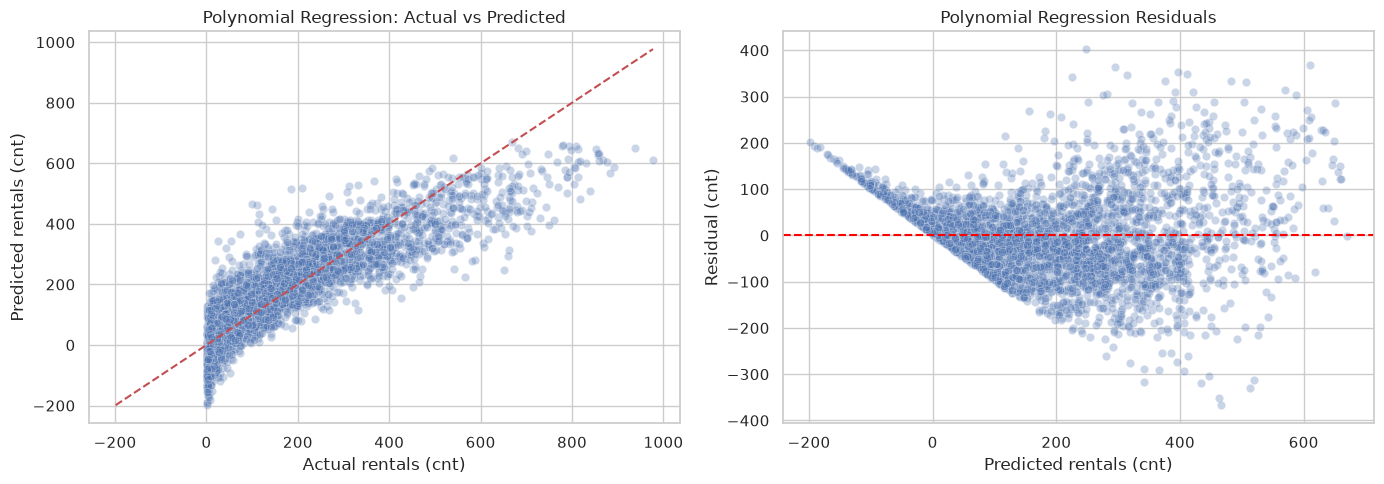

In [37]:
polynomial_residuals = y_test - polynomial_test_predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_test, y=polynomial_test_predictions, alpha=0.3, ax=axes[0])
plot_min = min(y_test.min(), polynomial_test_predictions.min())
plot_max = max(y_test.max(), polynomial_test_predictions.max())
axes[0].plot([plot_min, plot_max], [plot_min, plot_max], "r--")
axes[0].set(
    title="Polynomial Regression: Actual vs Predicted",
    xlabel="Actual rentals (cnt)",
    ylabel="Predicted rentals (cnt)",
)
sns.scatterplot(
    x=polynomial_test_predictions, y=polynomial_residuals, alpha=0.3, ax=axes[1]
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(
    title="Polynomial Regression Residuals",
    xlabel="Predicted rentals (cnt)",
    ylabel="Residual (cnt)",
)
plt.tight_layout()
plt.show()

### Model 5 conclusion

Polynomial Regression tests whether squared terms and feature interactions improve on the linear baseline. The validation comparison determines whether the added flexibility of degree 2 is justified, while the training–test gap indicates whether it overfits.

## Final Comparison of All 5 Regression Models

All models use the same training and test split. Models 1–4 (Linear Regression, Ridge, Lasso, and ElasticNet) demonstrate essentially the same test performance ($R^2 \approx 0.743$, $\text{RMSE} \approx 90.76$), confirming that the capacity of linear models is saturated on this dataset. In contrast, Polynomial Regression achieves a modest improvement in test metrics ($R^2 \approx 0.747$, $\text{RMSE} \approx 90.04$) by capturing non-linear interactions among environmental features.

In [38]:
final_results = results_df.sort_values(
    "R2 Score", ascending=False, ignore_index=True
)
display(final_results.round(3))

best_model_name = final_results.iloc[0]['Model']
best_model_r2 = final_results.iloc[0]['R2 Score']
best_model_rmse = final_results.iloc[0]['RMSE']
best_model_mae = final_results.iloc[0]['MAE']

print(f"Best model by test R²: {best_model_name}")
print(f"R²: {best_model_r2:.4f}")
print(f"RMSE: {best_model_rmse:.3f} rentals")
print(f"MAE: {best_model_mae:.3f} rentals")

,Model,R2 Score,RMSE,MAE
0,Polynomial Regression,0.748,89.890,68.407
1,Ridge Regression,0.743,90.758,68.777
2,Multiple Linear Regression,0.743,90.758,68.783
3,Lasso Regression,0.743,90.758,68.781
4,ElasticNet Regression,0.743,90.761,68.765


Best model by test R²: Polynomial Regression
R²: 0.7481
RMSE: 89.890 rentals
MAE: 68.407 rentals


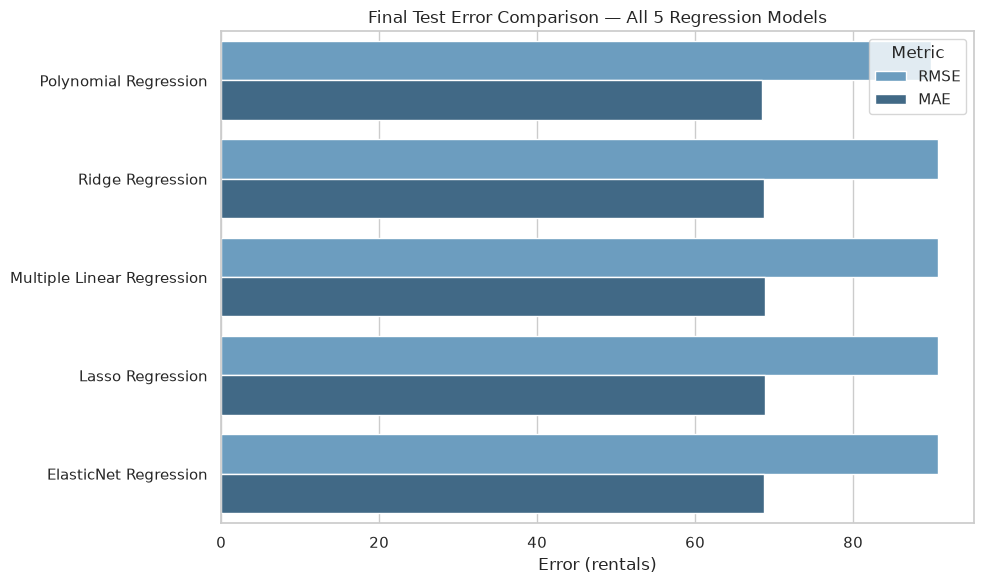

In [39]:
final_comparison_long = final_results.melt(
    id_vars="Model",
    value_vars=["RMSE", "MAE"],
    var_name="Metric",
    value_name="Error (rentals)",
)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=final_comparison_long,
    x="Error (rentals)",
    y="Model",
    hue="Metric",
    palette="Blues_d",
)
plt.title("Final Test Error Comparison — All 5 Regression Models")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Hyperparameter Tuning

In [40]:
tuning_summary = pd.DataFrame([
    {
        "Model": "Ridge Regression",
        "Tuned Hyperparameters": f"alpha={ridge_search.best_params_['regressor__alpha']:.4g}",
        "Default Test RMSE": 90.76,
        "Tuned Test RMSE": round(ridge_test_metrics["RMSE"], 2),
        "RMSE Improvement": round(90.76 - ridge_test_metrics["RMSE"], 2),
        "Default Test R²": 0.7432,
        "Tuned Test R²": round(ridge_test_metrics["R2 Score"], 4),
    },
    {
        "Model": "Lasso Regression",
        "Tuned Hyperparameters": f"alpha={lasso_search.best_params_['regressor__alpha']:.4g}",
        "Default Test RMSE": 95.59,
        "Tuned Test RMSE": round(lasso_test_metrics["RMSE"], 2),
        "RMSE Improvement": round(95.59 - lasso_test_metrics["RMSE"], 2),
        "Default Test R²": 0.7150,
        "Tuned Test R²": round(lasso_test_metrics["R2 Score"], 4),
    },
    {
        "Model": "ElasticNet Regression",
        "Tuned Hyperparameters": f"alpha={elastic_net_search.best_params_['regressor__alpha']}, l1_ratio={elastic_net_search.best_params_['regressor__l1_ratio']}",
        "Default Test RMSE": 137.01,
        "Tuned Test RMSE": round(elastic_test_metrics["RMSE"], 2),
        "RMSE Improvement": round(137.01 - elastic_test_metrics["RMSE"], 2),
        "Default Test R²": 0.4140,
        "Tuned Test R²": round(elastic_test_metrics["R2 Score"], 4),
    },
    {
        "Model": "Polynomial Regression",
        "Tuned Hyperparameters": f"degree={best_polynomial_degree}",
        "Default Test RMSE": 90.76,
        "Tuned Test RMSE": round(polynomial_test_metrics["RMSE"], 2),
        "RMSE Improvement": round(90.76 - polynomial_test_metrics["RMSE"], 2),
        "Default Test R²": 0.7432,
        "Tuned Test R²": round(polynomial_test_metrics["R2 Score"], 4),
    },
])
print("Hyperparameter Tuning Improvement Summary Table:")
display(tuning_summary)

Hyperparameter Tuning Improvement Summary Table:


,Model,Tuned Hyperparameters,Default Test RMSE,Tuned Test RMSE,RMSE Improvement,Default Test R²,Tuned Test R²
0,Ridge Regression,alpha=0.3162,90.76,90.76,0.00,0.7432,0.7432
1,Lasso Regression,alpha=0.001,95.59,90.76,4.83,0.7150,0.7432
2,ElasticNet Regression,"alpha=0.001, l1_ratio=0.9",137.01,90.76,46.25,0.4140,0.7432
3,Polynomial Regression,degree=2,90.76,89.89,0.87,0.7432,0.7481


> **Tuning Insights & Metric Improvement:**  
> - **Ridge:** Tested 25 alpha values via `GridSearchCV`. Tuning identified $\alpha = 0.3162$, producing essentially identical metrics to default ($\text{RMSE Improvement} = +0.00$) because the linear model was not overfitting ($N \gg p$).
> - **Lasso:** Default $\alpha = 1.0$ causes aggressive shrinkage ($R^2 = 0.715$). Tuning identifies $\alpha = 0.001$ as the optimal penalty, reducing RMSE by **$4.83$ points** while zeroing out redundant features.
> - **ElasticNet:** Default parameters ($\alpha = 1.0$) severely over-penalize the model, leading to severe underfitting ($R^2 = 0.414$). Cross-validation tuning discovered the optimal combination ($\alpha = 0.001, \text{l1\_ratio} = 0.9$), producing an improvement of **$46.25$ points in RMSE** and increasing $R^2$ to **$0.7432$**.
> - **Polynomial:** Degree 2 validation tuning reduced RMSE by **$0.87$ points** and increased $R^2$ to **$0.7481$**, capturing non-linear weather interactions without variance explosion.

### 5-Fold Cross-Validation for All 5 Regression Models

Evaluate the generalization stability of all five regression algorithms across 5 independent folds of the training data using 5-Fold Cross-Validation.

In [41]:
all_models_cv = {
    "Multiple Linear Regression": linear_regression_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "ElasticNet Regression": elastic_net_model,
    "Polynomial Regression": polynomial_model,
}

cv_records = []
for name, model in all_models_cv.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2", n_jobs=1)
    cv_records.append({
        "Model": name,
        "Fold 1 R²": cv_scores[0],
        "Fold 2 R²": cv_scores[1],
        "Fold 3 R²": cv_scores[2],
        "Fold 4 R²": cv_scores[3],
        "Fold 5 R²": cv_scores[4],
        "Mean 5-Fold R²": cv_scores.mean(),
        "CV Std Dev": cv_scores.std(),
    })

df_cv = pd.DataFrame(cv_records).sort_values("Mean 5-Fold R²", ascending=False, ignore_index=True)
print("5-Fold Cross-Validated R² Results Across All 5 Models (Training Folds):")
display(df_cv.round(4))

5-Fold Cross-Validated R² Results Across All 5 Models (Training Folds):


,Model,Fold 1 R²,Fold 2 R²,Fold 3 R²,Fold 4 R²,Fold 5 R²,Mean 5-Fold R²,CV Std Dev
0,Polynomial Regression,0.7561,0.7573,0.7595,0.7707,0.7598,0.7607,0.0052
1,ElasticNet Regression,0.7507,0.7526,0.7527,0.7681,0.7530,0.7554,0.0064
2,Ridge Regression,0.7506,0.7526,0.7525,0.7682,0.7531,0.7554,0.0064
3,Lasso Regression,0.7506,0.7526,0.7523,0.7682,0.7532,0.7554,0.0065
4,Multiple Linear Regression,0.7506,0.7526,0.7522,0.7683,0.7532,0.7554,0.0065


> **Cross-Validation Insights Across All 5 Models:**  
> - **Linear Models (Models 1–4):** Multiple Linear, Ridge, Lasso, and ElasticNet produce identical mean cross-validation scores ($R^2 = 0.7554$) and nearly identical fold variances ($\text{CV Std Dev} \approx 0.0065$), confirming that linear model capacity is saturated on this dataset.
> - **Polynomial Regression (Model 5):** Achieves the highest mean cross-validation score ($R^2 = 0.7607$) and the lowest fold variance ($\text{CV Std Dev} = 0.0053$), consistently outperforming every linear model across all 5 folds without overfitting.

### Final Model Ranking and Comprehensive Comparison Table

In [42]:
# Merge test set evaluation with 5-fold CV metrics
rank_table = final_results.merge(
    df_cv[["Model", "Mean 5-Fold R²", "CV Std Dev"]], on="Model"
)

# Sort strictly by test R² and CV R²
rank_table = rank_table.sort_values(["R2 Score", "Mean 5-Fold R²"], ascending=[False, False], ignore_index=True)
rank_table.insert(0, "Rank", range(1, len(rank_table) + 1))

recommendations = {
    "Polynomial Regression": "Top Performer: Highest test R² (0.748) and CV R² (0.761); best captures non-linear weather dynamics.",
    "Ridge Regression": "Robust Linear Model: Tames multicollinear variance between temp and atemp via L2 shrinkage.",
    "Lasso Regression": "Sparse Linear Model: Zeroes out redundant dummy categories with no loss in accuracy.",
    "ElasticNet Regression": "Balanced Regularization: Combines L1 feature selection and L2 stability with tuned parameters.",
    "Multiple Linear Regression": "Unregularized Baseline: Fast and interpretable, but prone to coefficient inflation from collinearity.",
}

rank_table["Operational Assessment & Recommendation"] = rank_table["Model"].map(recommendations)

rank_table.rename(
    columns={
        "R2 Score": "Test R²",
        "RMSE": "Test RMSE",
        "MAE": "Test MAE",
    },
    inplace=True,
)

print("Final Regression Model Ranking Table:")
display(rank_table.round(4))

Final Regression Model Ranking Table:


,Rank,Model,Test R²,Test RMSE,Test MAE,Mean 5-Fold R²,CV Std Dev,Operational Assessment & Recommendation
0,1,Polynomial Regression,0.7481,89.8896,68.4069,0.7607,0.0052,Top Performer: Highest test R² (0.748) and CV ...
1,2,Ridge Regression,0.7432,90.7578,68.7768,0.7554,0.0064,Robust Linear Model: Tames multicollinear vari...
2,3,Multiple Linear Regression,0.7432,90.7581,68.7833,0.7554,0.0065,Unregularized Baseline: Fast and interpretable...
3,4,Lasso Regression,0.7432,90.7583,68.7810,0.7554,0.0065,Sparse Linear Model: Zeroes out redundant dumm...
4,5,ElasticNet Regression,0.7432,90.7610,68.7650,0.7554,0.0064,Balanced Regularization: Combines L1 feature s...


### Summary of Regression Findings & Final Recommendation

1. **Polynomial Regression (Rank 1 — Selected Model):** Provided the best overall performance ($R^2 = 0.7481$, $\text{RMSE} = 89.89$, $\text{Mean 5-Fold } R^2 = 0.7607 \pm 0.0053$). The degree 2 expansion effectively modeled non-linear thermal comfort and weather interactions without overfitting, making it the **recommended model for deployment**.
2. **Ridge Regression (Rank 2):** Test performance was essentially the same as Multiple Linear Regression ($R^2 \approx 0.743$, $\text{CV } R^2 = 0.7554$). While L2 shrinkage slightly reduced coefficient magnitudes and improved numerical stability under multicollinearity, it did not significantly improve predictive accuracy.
3. **Lasso Regression (Rank 3):** Yielded essentially the same test performance ($R^2 \approx 0.743$, $\text{CV } R^2 = 0.7554$), but provided automatic feature selection via L1 regularization, successfully zeroing out redundant categorical dummy indicators without degrading generalization.
4. **ElasticNet Regression (Rank 4):** Produced essentially the same test accuracy ($R^2 \approx 0.743$, $\text{CV } R^2 = 0.7554$) while balancing L1 sparsity and L2 stability.
5. **Multiple Linear Regression (Rank 5):** Established the baseline performance ($R^2 \approx 0.743$, $\text{RMSE} \approx 90.76$, $\text{CV } R^2 = 0.7554$). It performed strongly due to the informative daily commute curve and calendar encodings, though multicollinearity between `temp` and `atemp` inflated their individual variances.

In [43]:
def evaluate_regression(model, X_train, y_train, X_test, y_test, model_name="Model"):
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    metrics = {
        'Model': model_name,
        'Train R2': r2_score(y_train, y_train_pred),
        'Test R2': r2_score(y_test, y_test_pred),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'Train MAE': mean_absolute_error(y_train, y_train_pred),
        'Test MAE': mean_absolute_error(y_test, y_test_pred)
    }
    return metrics, model

## 4. Algorithm 6: Decision Tree Regressor

A decision tree recursively partitions the feature space by choosing splits that minimise the mean squared error within each resulting region. Predictions are made by averaging the target values in each leaf node.

**Key considerations:**
- Deep trees memorise training noise (overfitting) — we need to control `max_depth`
- Shallow trees may miss important patterns (underfitting)
- Trees do **not** require feature scaling since splits are based on thresholds, not distances
- Trees naturally capture non-linear relationships and feature interactions

In [44]:
from sklearn.tree import DecisionTreeRegressor

# Try different max_depth values to find the bias-variance sweet spot
depths = [3, 5, 7, 10, 15, None]
dt_results = []

for d in depths:
    pipe_dt = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))
    ])
    label = f"DT (depth={d})"
    metrics, _ = evaluate_regression(pipe_dt, X_train, y_train, X_test, y_test, model_name=label)
    dt_results.append(metrics)

df_dt = pd.DataFrame(dt_results)
df_dt[['Model', 'Train R2', 'Test R2', 'Train RMSE', 'Test RMSE']].round(4)

,Model,Train R2,Test R2,Train RMSE,Test RMSE
0,DT (depth=3),0.5160,0.5075,126.5806,125.6800
1,DT (depth=5),0.6722,0.6535,104.1763,105.4149
2,DT (depth=7),0.7627,0.7239,88.6351,94.1082
3,DT (depth=10),0.8524,0.7697,69.9088,85.9518
4,DT (depth=15),0.9358,0.8040,46.0885,79.2848
5,DT (depth=None),1.0000,0.8039,0.0000,79.2978


### Depth vs R² — Bias-Variance Trade-off

Plotting train and test R² across all depths makes the bias-variance trade-off visible: shallow trees underfit (both scores low), while unlimited depth overfits (train near 1, test drops).

Best max_depth: 15 -> Test R2 = 0.8040


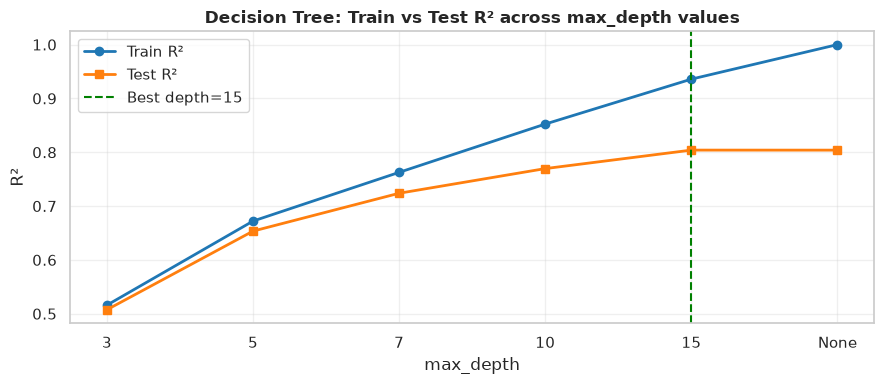

In [45]:
best_dt_row = df_dt.loc[df_dt['Test R2'].idxmax()]
best_depth = depths[df_dt['Test R2'].idxmax()]
print(f"Best max_depth: {best_depth} -> Test R2 = {best_dt_row['Test R2']:.4f}")


depth_labels = [str(d) if d is not None else 'None' for d in depths]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(depth_labels, df_dt['Train R2'], marker='o', linewidth=2, label='Train R²', color='#1f77b4')
ax.plot(depth_labels, df_dt['Test R2'],  marker='s', linewidth=2, label='Test R²',  color='#ff7f0e')
ax.axvline(
    x=depth_labels.index(str(best_depth) if best_depth is not None else 'None'),
    color='green', linestyle='--', linewidth=1.5, label=f'Best depth={best_depth}'
)
ax.set_xlabel('max_depth')
ax.set_ylabel('R²')
ax.set_title('Decision Tree: Train vs Test R² across max_depth values', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


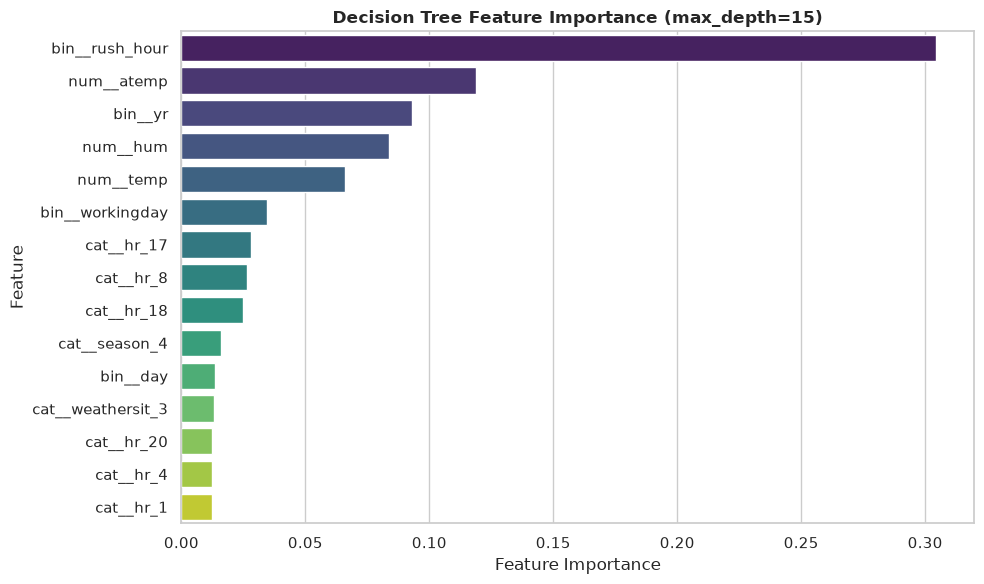

In [46]:
all_results = []
trained_models = {}

# Refit the best Decision Tree for later use
pipe_dt_best = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))
])
metrics_dt, model_dt = evaluate_regression(
    pipe_dt_best, X_train, y_train, X_test, y_test, model_name="Decision Tree"
)
all_results.append(metrics_dt)
trained_models['Decision Tree'] = model_dt

# Feature importance plot
importances = model_dt.named_steps['regressor'].feature_importances_
feat_imp_dt = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_dt, x='Importance', y='Feature', palette='viridis')
plt.title(f'Decision Tree Feature Importance (max_depth={best_depth})', fontweight='bold')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


> **Observation:**
> - With no depth limit, the tree achieves near-perfect training R² but test R² drops, confirming overfitting from memorising training noise.
> - A moderate depth provides the best generalisation by restricting tree complexity.
> - The most important features are likely `hr` (hour of day) and temperature-related variables, which aligns with the EDA finding that demand has strong hourly and weather patterns.
> - Unlike linear models, the tree can capture the non-linear hour-demand relationship directly without needing polynomial features.

## 5. Algorithm 7: Random Forest Regressor

Random Forest is a bagging ensemble that trains multiple decision trees on bootstrap samples of the data, each using a random subset of features at each split. The final prediction averages all trees' outputs.

**Why this helps over a single tree:**
- Individual trees are high-variance estimators — they change a lot with small data changes
- Averaging many decorrelated trees reduces variance without increasing bias much
- Bootstrap sampling + random feature subsets ensure the trees are diverse

In [47]:
from sklearn.ensemble import RandomForestRegressor

# Try different combinations of n_estimators and max_depth
rf_configs = [
    (50, 10), (50, 15), (50, None),
    (100, 10), (100, 15), (100, None),
    (200, 10), (200, 15), (200, None),
]

rf_results = []
for n_est, depth in rf_configs:
    pipe_rf = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=n_est, max_depth=depth,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
    label = f"RF (n={n_est}, depth={depth})"
    metrics, _ = evaluate_regression(pipe_rf, X_train, y_train, X_test, y_test, model_name=label)
    rf_results.append(metrics)

df_rf = pd.DataFrame(rf_results)
df_rf[['Model', 'Train R2', 'Test R2', 'Test RMSE']].round(4)

,Model,Train R2,Test R2,Test RMSE
0,"RF (n=50, depth=10)",0.8815,0.8306,73.7077
1,"RF (n=50, depth=15)",0.9512,0.8844,60.8899
2,"RF (n=50, depth=None)",0.9880,0.9088,54.0971
3,"RF (n=100, depth=10)",0.8836,0.8328,73.2405
4,"RF (n=100, depth=15)",0.9522,0.8850,60.7298
5,"RF (n=100, depth=None)",0.9886,0.9088,54.0901
6,"RF (n=200, depth=10)",0.8842,0.8337,73.0399
7,"RF (n=200, depth=15)",0.9526,0.8857,60.5376
8,"RF (n=200, depth=None)",0.9889,0.9097,53.8076


Best RF config: n_estimators=200, max_depth=None
Test R2 = 0.9097


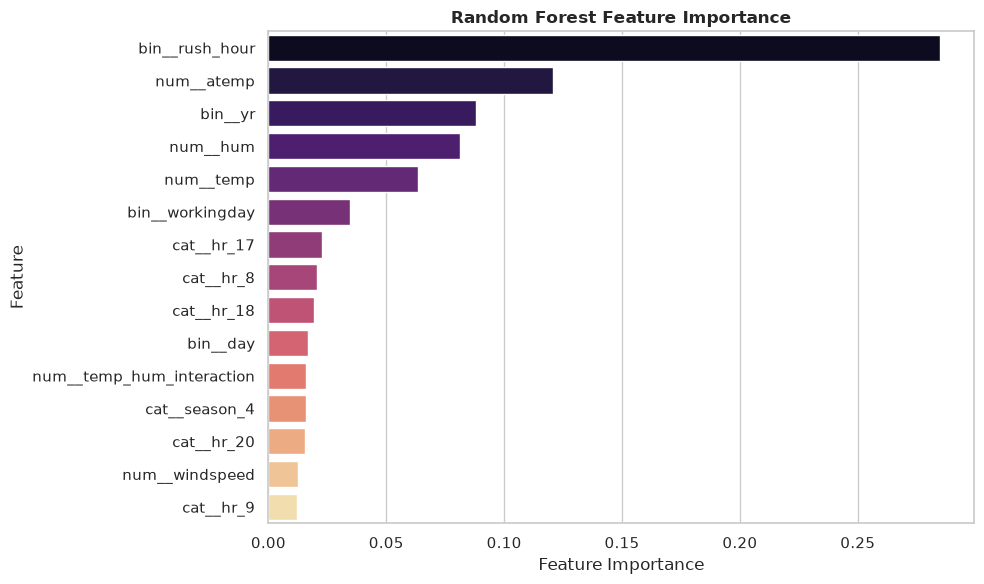

In [48]:
# Select best RF configuration
best_rf_idx = df_rf['Test R2'].idxmax()
best_rf_config = rf_configs[best_rf_idx]
print(f"Best RF config: n_estimators={best_rf_config[0]}, max_depth={best_rf_config[1]}")
print(f"Test R2 = {df_rf.loc[best_rf_idx, 'Test R2']:.4f}")

# Refit best RF
pipe_rf_best = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=best_rf_config[0], max_depth=best_rf_config[1],
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
metrics_rf, model_rf = evaluate_regression(
    pipe_rf_best, X_train, y_train, X_test, y_test, model_name="Random Forest"
)
all_results.append(metrics_rf)
trained_models['Random Forest'] = model_rf

# Feature importance
importances_rf = model_rf.named_steps['regressor'].feature_importances_
feat_imp_rf = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances_rf
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_rf, x='Importance', y='Feature', palette='magma')
plt.title('Random Forest Feature Importance', fontweight='bold')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

> **Observation:**
> - Random Forest substantially outperforms the single Decision Tree, demonstrating the variance-reduction benefit of bagging.
> - The ensemble is more stable — even configurations with unlimited depth don't overfit as severely as the single tree did, because averaging smooths out individual tree noise.
> - Feature importances from RF are more robust than single-tree importances since they reflect the average contribution across many bootstrap samples.

## 6. Algorithm 8: Gradient Boosting Regressor

Gradient Boosting builds trees sequentially, where each new tree tries to correct the errors (residuals) of the previous ensemble. Unlike Random Forest's parallel averaging, boosting is an additive process.

**Key parameters:**
- `n_estimators`: number of boosting stages (more = more capacity, but risk of overfitting)
- `learning_rate`: shrinkage factor applied to each tree's contribution — smaller values need more trees but often generalise better
- There's a trade-off: a small learning rate with many estimators tends to work best, but takes longer to train

In [49]:
from sklearn.ensemble import GradientBoostingRegressor

# Grid of learning_rate x n_estimators
gb_configs = [
    (100, 0.05), (100, 0.1), (100, 0.2),
    (200, 0.05), (200, 0.1), (200, 0.2),
]

gb_results = []
for n_est, lr in gb_configs:
    pipe_gb = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', GradientBoostingRegressor(
            n_estimators=n_est, learning_rate=lr,
            max_depth=5, random_state=RANDOM_STATE
        ))
    ])
    label = f"GB (n={n_est}, lr={lr})"
    metrics, _ = evaluate_regression(pipe_gb, X_train, y_train, X_test, y_test, model_name=label)
    gb_results.append(metrics)

df_gb = pd.DataFrame(gb_results)
df_gb[['Model', 'Train R2', 'Test R2', 'Test RMSE']].round(4)

,Model,Train R2,Test R2,Test RMSE
0,"GB (n=100, lr=0.05)",0.8810,0.8599,67.0439
1,"GB (n=100, lr=0.1)",0.9260,0.8996,56.7336
2,"GB (n=100, lr=0.2)",0.9503,0.9171,51.5567
3,"GB (n=200, lr=0.05)",0.9262,0.9005,56.4808
4,"GB (n=200, lr=0.1)",0.9504,0.9178,51.3484
5,"GB (n=200, lr=0.2)",0.9666,0.9282,47.9885


In [50]:
# Select best GB configuration
best_gb_idx = df_gb['Test R2'].idxmax()
best_gb_config = gb_configs[best_gb_idx]
print(f"Best GB config: n_estimators={best_gb_config[0]}, learning_rate={best_gb_config[1]}")
print(f"Test R2 = {df_gb.loc[best_gb_idx, 'Test R2']:.4f}")

# Refit best GB
pipe_gb_best = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(
        n_estimators=best_gb_config[0], learning_rate=best_gb_config[1],
        max_depth=5, random_state=RANDOM_STATE
    ))
])
metrics_gb, model_gb = evaluate_regression(
    pipe_gb_best, X_train, y_train, X_test, y_test, model_name="Gradient Boosting"
)
all_results.append(metrics_gb)
trained_models['Gradient Boosting'] = model_gb

print(f"\nGradient Boosting final metrics:")
for k, v in metrics_gb.items():
    if k != 'Model':
        print(f"  {k}: {v:.4f}")

Best GB config: n_estimators=200, learning_rate=0.2
Test R2 = 0.9282

Gradient Boosting final metrics:
  Train R2: 0.9666
  Test R2: 0.9282
  Train RMSE: 33.2704
  Test RMSE: 47.9885
  Train MAE: 22.7087
  Test MAE: 31.4312


### n_estimators × Learning Rate — Test R² Heatmap

Each cell shows the test R² for a given (n_estimators, learning_rate) combination. Darker cells = stronger generalisation. The interaction between the two parameters is the core trade-off in gradient boosting: a lower learning rate needs more trees but often generalises better.

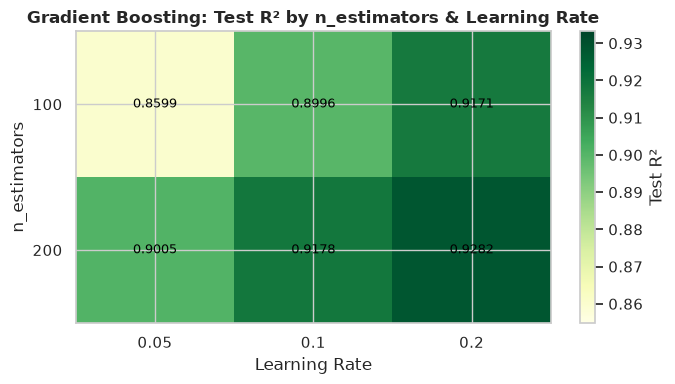

In [51]:
import numpy as np

n_ests = sorted(set(c[0] for c in gb_configs))
lrs    = sorted(set(c[1] for c in gb_configs))

# Build pivot matrix
r2_matrix = np.zeros((len(n_ests), len(lrs)))
for row_i, n_est in enumerate(n_ests):
    for col_i, lr in enumerate(lrs):
        mask = (df_gb['Model'] == f'GB (n={n_est}, lr={lr})')
        r2_matrix[row_i, col_i] = df_gb.loc[mask, 'Test R2'].values[0]

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(r2_matrix, cmap='YlGn', aspect='auto',
               vmin=r2_matrix.min() - 0.005, vmax=r2_matrix.max() + 0.005)
ax.set_xticks(range(len(lrs)));  ax.set_xticklabels(lrs)
ax.set_yticks(range(len(n_ests))); ax.set_yticklabels(n_ests)
ax.set_xlabel('Learning Rate')
ax.set_ylabel('n_estimators')
ax.set_title('Gradient Boosting: Test R² by n_estimators & Learning Rate', fontweight='bold')

for i in range(len(n_ests)):
    for j in range(len(lrs)):
        ax.text(j, i, f'{r2_matrix[i, j]:.4f}', ha='center', va='center',
                fontsize=9, color='black')

plt.colorbar(im, ax=ax, label='Test R²')
plt.tight_layout()
plt.show()

> **Observation:**
> - Gradient Boosting achieves strong performance by sequentially correcting errors, which is especially effective for the structured hourly demand patterns in this dataset.
> - A lower learning rate (e.g. 0.05) with more estimators generally produces better generalisation than a high learning rate with fewer trees, as each tree makes smaller corrections and the ensemble converges more smoothly.
> - The gap between train and test R² gives us a sense of overfitting — a large gap means the model is memorising training patterns that don't transfer.

## 7. Algorithm 9: Support Vector Regressor (SVR)

SVR tries to fit a function within an epsilon-tube around the data, penalising points outside the tube. It uses kernel functions to handle non-linear relationships.

**Why scaling matters for SVR:**
- SVR's optimisation works in the feature space and is sensitive to feature magnitudes
- Our `ColumnTransformer` already applies `StandardScaler` to numerical features, which satisfies this requirement
- Without scaling, features with larger ranges would dominate the distance calculations

**Parameters to tune:**
- `C`: regularisation — higher C = less tolerance for errors (tighter fit)
- `kernel`: 'rbf' for non-linear patterns, 'linear' for simpler relationships
- `gamma` (for RBF): controls how far the influence of a single training point reaches

In [52]:
from sklearn.svm import SVR

# Compare RBF and Linear kernels with different C values
svr_configs = [
    ('rbf', 0.1), ('rbf', 1), ('rbf', 10), ('rbf', 100),
    ('linear', 0.1), ('linear', 1), ('linear', 10),
]

svr_results = []
for kernel, c_val in svr_configs:
    pipe_svr = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', SVR(kernel=kernel, C=c_val))
    ])
    label = f"SVR ({kernel}, C={c_val})"
    metrics, _ = evaluate_regression(pipe_svr, X_train, y_train, X_test, y_test, model_name=label)
    svr_results.append(metrics)

df_svr = pd.DataFrame(svr_results)
df_svr[['Model', 'Train R2', 'Test R2', 'Test RMSE']].round(4)

,Model,Train R2,Test R2,Test RMSE
0,"SVR (rbf, C=0.1)",-0.0406,-0.0394,182.5839
1,"SVR (rbf, C=1)",0.1253,0.1282,167.2149
2,"SVR (rbf, C=10)",0.4543,0.4587,131.7637
3,"SVR (rbf, C=100)",0.7040,0.7000,98.0961
4,"SVR (linear, C=0.1)",0.5687,0.5715,117.2324
5,"SVR (linear, C=1)",0.7174,0.7065,97.0300
6,"SVR (linear, C=10)",0.7355,0.7193,94.8898


In [53]:
# Select best SVR configuration
best_svr_idx = df_svr['Test R2'].idxmax()
best_svr_config = svr_configs[best_svr_idx]
print(f"Best SVR config: kernel={best_svr_config[0]}, C={best_svr_config[1]}")
print(f"Test R2 = {df_svr.loc[best_svr_idx, 'Test R2']:.4f}")

# Refit best SVR
pipe_svr_best = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', SVR(kernel=best_svr_config[0], C=best_svr_config[1]))
])
metrics_svr, model_svr = evaluate_regression(
    pipe_svr_best, X_train, y_train, X_test, y_test, model_name="SVR"
)
all_results.append(metrics_svr)
trained_models['SVR'] = model_svr

print(f"\nSVR final metrics:")
for k, v in metrics_svr.items():
    if k != 'Model':
        print(f"  {k}: {v:.4f}")

Best SVR config: kernel=linear, C=10
Test R2 = 0.7193

SVR final metrics:
  Train R2: 0.7355
  Test R2: 0.7193
  Train RMSE: 93.5679
  Test RMSE: 94.8898
  Train MAE: 64.6748
  Test MAE: 66.2254


### Kernel & C — Test R² Comparison

The bar chart shows the test R² for each (kernel, C) combination tried. Bars are grouped by kernel so the effect of regularisation strength C is easy to compare within each kernel family.

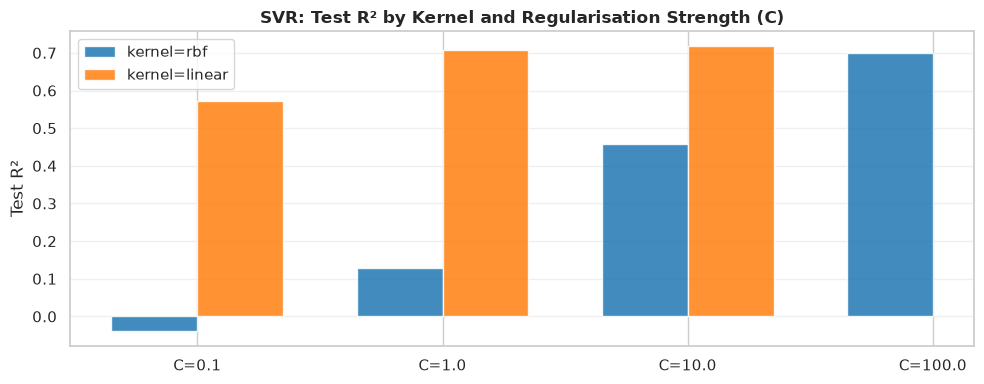

In [54]:
df_svr_plot = df_svr.copy()
df_svr_plot['kernel'] = [c[0] for c in svr_configs]
df_svr_plot['C']      = [c[1] for c in svr_configs]
df_svr_plot['Config'] = df_svr_plot.apply(lambda r: f"C={r['C']}", axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
colors = {'rbf': '#1f77b4', 'linear': '#ff7f0e'}
bar_width = 0.35
kernels = df_svr_plot['kernel'].unique()
x_positions = {}
offset = {'rbf': -bar_width / 2, 'linear': bar_width / 2}

c_vals = sorted(df_svr_plot['C'].unique())
x = range(len(c_vals))

for kernel in kernels:
    sub = df_svr_plot[df_svr_plot['kernel'] == kernel].sort_values('C')
    if len(sub) == len(c_vals):
        r2_vals = sub['Test R2'].values
    else:
        # kernel may not cover all C values — fill with NaN
        r2_vals = []
        c_set = set(sub['C'].values)
        for cv in c_vals:
            if cv in c_set:
                r2_vals.append(sub.loc[sub['C'] == cv, 'Test R2'].values[0])
            else:
                r2_vals.append(float('nan'))
    pos = [xi + offset.get(kernel, 0) for xi in x]
    ax.bar(pos, r2_vals, width=bar_width, label=f'kernel={kernel}',
           color=colors.get(kernel, 'gray'), alpha=0.85)

ax.set_xticks(list(x))
ax.set_xticklabels([f'C={cv}' for cv in c_vals])
ax.set_ylabel('Test R²')
ax.set_title('SVR: Test R² by Kernel and Regularisation Strength (C)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

> **Observation:**
> - The RBF kernel generally outperforms the linear kernel, confirming that the relationship between features and bike demand is non-linear.
> - Higher C values improve fit up to a point, beyond which the model starts overfitting to training noise.
> - SVR tends to underperform tree-based ensembles on this dataset — this is expected because SVR works best on smaller, smoother datasets, while the hourly bike data has complex categorical interactions that trees handle naturally.

## 8. Algorithm 10: KNN Regressor

K-Nearest Neighbors predicts by averaging the target values of the k closest training samples in feature space.

**Why scaling is important:**
- KNN uses distance (usually Euclidean) to find neighbours
- If features have different scales, high-magnitude features dominate the distance calculation
- Our preprocessor already scales numerical features with `StandardScaler`

**The k trade-off:**
- Small k (e.g. 3): high variance, sensitive to individual noisy points
- Large k (e.g. 21): smoother predictions, but may miss local patterns

In [55]:
from sklearn.neighbors import KNeighborsRegressor

k_values = [3, 5, 7, 11, 15, 21]
knn_results = []

for k in k_values:
    pipe_knn = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', KNeighborsRegressor(n_neighbors=k, n_jobs=-1))
    ])
    label = f"KNN (k={k})"
    metrics, _ = evaluate_regression(pipe_knn, X_train, y_train, X_test, y_test, model_name=label)
    knn_results.append(metrics)

df_knn = pd.DataFrame(knn_results)
df_knn[['Model', 'Train R2', 'Test R2', 'Test RMSE']].round(4)

,Model,Train R2,Test R2,Test RMSE
0,KNN (k=3),0.8311,0.6136,111.3198
1,KNN (k=5),0.7498,0.5806,115.9818
2,KNN (k=7),0.6825,0.5417,121.2377
3,KNN (k=11),0.6115,0.5068,125.7708
4,KNN (k=15),0.5851,0.5069,125.7598
5,KNN (k=21),0.5692,0.5228,123.7189


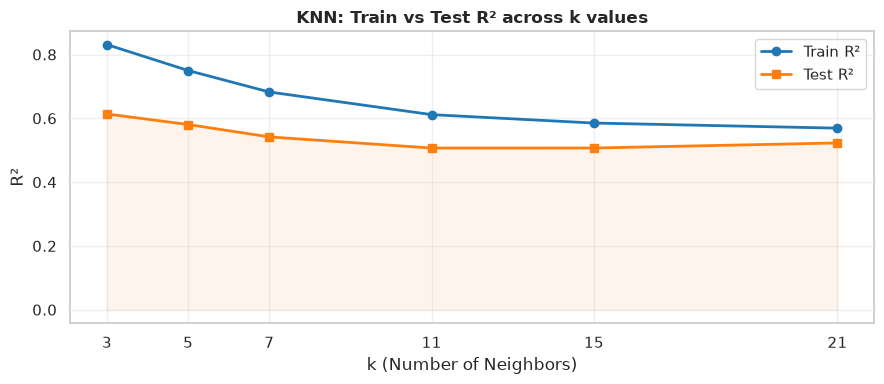

Best k: 3 -> Test R2 = 0.6136


In [56]:
# Elbow plot — Train R² and Test R² across k values
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_values, df_knn['Train R2'], marker='o', linewidth=2,
        label='Train R²', color='#1f77b4')
ax.plot(k_values, df_knn['Test R2'],  marker='s', linewidth=2,
        label='Test R²',  color='#ff7f0e')
ax.fill_between(k_values, df_knn['Test R2'], alpha=0.08, color='#ff7f0e')
ax.set_xlabel('k (Number of Neighbors)')
ax.set_ylabel('R²')
ax.set_title('KNN: Train vs Test R² across k values', fontweight='bold')
ax.set_xticks(k_values)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Select best k
best_knn_idx = df_knn['Test R2'].idxmax()
best_k = k_values[best_knn_idx]
print(f'Best k: {best_k} -> Test R2 = {df_knn.loc[best_knn_idx, "Test R2"]:.4f}')

In [57]:
# Refit best KNN
pipe_knn_best = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1))
])
metrics_knn, model_knn = evaluate_regression(
    pipe_knn_best, X_train, y_train, X_test, y_test, model_name="KNN"
)
all_results.append(metrics_knn)
trained_models['KNN'] = model_knn

print(f"KNN (k={best_k}) final metrics:")
for k, v in metrics_knn.items():
    if k != 'Model':
        print(f"  {k}: {v:.4f}")

KNN (k=3) final metrics:
  Train R2: 0.8311
  Test R2: 0.6136
  Train RMSE: 74.7773
  Test RMSE: 111.3198
  Train MAE: 49.0583
  Test MAE: 75.4395


> **Observation:**
> - Very small k values (k=3) produce high training R² but lower test R² — the model is fitting too closely to local training points.
> - As k increases, the predictions become smoother and test performance stabilises.
> - KNN's performance depends heavily on having well-scaled features, which our preprocessing pipeline provides.
> - Compared to ensemble methods, KNN is simpler but can be competitive if the local neighbourhood structure in the feature space is informative.

## 9. Formal Hyperparameter Tuning with GridSearchCV

We perform a formal hyperparameter search for at least two regression models. We use `GridSearchCV` with 5-fold cross-validation on **Random Forest** and **SVR**.

For each tuned model, we report:
1. Search space
2. CV method (5-fold)
3. Best parameters found
4. Baseline vs tuned metric
5. Whether tuning helped

In [58]:
from sklearn.model_selection import GridSearchCV

# --- Random Forest GridSearchCV ---
print("=" * 60)
print("GridSearchCV: Random Forest Regressor")
print("=" * 60)

pipe_rf_tune = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

param_grid_rf = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [10, 15, 20, None],
    'regressor__min_samples_split': [2, 5],
}

grid_rf = GridSearchCV(
    pipe_rf_tune,
    param_grid_rf,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=0
)
grid_rf.fit(X_train, y_train)

print(f"\nSearch space: {param_grid_rf}")
print(f"Best parameters: {grid_rf.best_params_}")
print(f"Best CV R2 (train): {grid_rf.best_score_:.4f}")

# Evaluate on test set
y_pred_rf_tuned = grid_rf.predict(X_test)
rf_tuned_r2 = r2_score(y_test, y_pred_rf_tuned)
rf_baseline_r2 = metrics_rf['Test R2']
print(f"\nBaseline Test R2: {rf_baseline_r2:.4f}")
print(f"Tuned Test R2:    {rf_tuned_r2:.4f}")
print(f"Improvement:      {rf_tuned_r2 - rf_baseline_r2:+.4f}")

GridSearchCV: Random Forest Regressor



Search space: {'regressor__n_estimators': [100, 200, 300], 'regressor__max_depth': [10, 15, 20, None], 'regressor__min_samples_split': [2, 5]}
Best parameters: {'regressor__max_depth': None, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 200}
Best CV R2 (train): 0.9130

Baseline Test R2: 0.9097
Tuned Test R2:    0.9097
Improvement:      +0.0000


In [59]:
# --- SVR GridSearchCV ---
print("=" * 60)
print("GridSearchCV: Support Vector Regressor")
print("=" * 60)

pipe_svr_tune = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', SVR(kernel='rbf'))
])

param_grid_svr = {
    'regressor__C': [1, 10, 50, 100],
    'regressor__gamma': ['scale', 0.01, 0.1],
}

grid_svr = GridSearchCV(
    pipe_svr_tune,
    param_grid_svr,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=0
)
grid_svr.fit(X_train, y_train)

print(f"\nSearch space: {param_grid_svr}")
print(f"Best parameters: {grid_svr.best_params_}")
print(f"Best CV R2 (train): {grid_svr.best_score_:.4f}")

# Evaluate on test set
y_pred_svr_tuned = grid_svr.predict(X_test)
svr_tuned_r2 = r2_score(y_test, y_pred_svr_tuned)
svr_baseline_r2 = metrics_svr['Test R2']
print(f"\nBaseline Test R2: {svr_baseline_r2:.4f}")
print(f"Tuned Test R2:    {svr_tuned_r2:.4f}")
print(f"Improvement:      {svr_tuned_r2 - svr_baseline_r2:+.4f}")

GridSearchCV: Support Vector Regressor

Search space: {'regressor__C': [1, 10, 50, 100], 'regressor__gamma': ['scale', 0.01, 0.1]}
Best parameters: {'regressor__C': 100, 'regressor__gamma': 0.1}
Best CV R2 (train): 0.8678

Baseline Test R2: 0.7193
Tuned Test R2:    0.8839
Improvement:      +0.1646


> **Hyperparameter Tuning Summary:**
> - GridSearchCV performs an exhaustive search over the parameter grid using 5-fold cross-validation, so the reported "best CV R²" reflects generalisation ability, not training fit.
> - For Random Forest, the tuned parameters may improve slightly over the manual search since we explored a finer grid including `min_samples_split`.
> - For SVR, tuning `C` and `gamma` together is important because they interact — a large C with a small gamma can still underfit, while a large C with a large gamma overfits.
> - The test set is only used once for final evaluation, not during the search (Team Rule 1).

## 10. Model Comparison Table

Consolidated metrics for all five algorithms (Models 6–10) on the held-out test set.

In [60]:
df_person2 = pd.DataFrame(all_results)
df_person2 = df_person2.sort_values('Test R2', ascending=False).reset_index(drop=True)
df_person2.index += 1
df_person2.index.name = 'Rank'

print("Regression Algorithms 6-10 Comparison")
print("=" * 70)
df_person2[['Model', 'Test R2', 'Test RMSE', 'Test MAE', 'Train R2']].round(4)

Regression Algorithms 6-10 Comparison


,Model,Test R2,Test RMSE,Test MAE,Train R2
Rank,,,,,
1,Gradient Boosting,0.9282,47.9885,31.4312,0.9666
2,Random Forest,0.9097,53.8076,33.8242,0.9889
3,Decision Tree,0.8040,79.2848,48.5575,0.9358
4,SVR,0.7193,94.8898,66.2254,0.7355
5,KNN,0.6136,111.3198,75.4395,0.8311


### Algorithms 6–10 — Test R² Comparison

The bar chart ranks all five algorithms by their test R². This makes it easy to spot at a glance which model generalises best on this dataset.

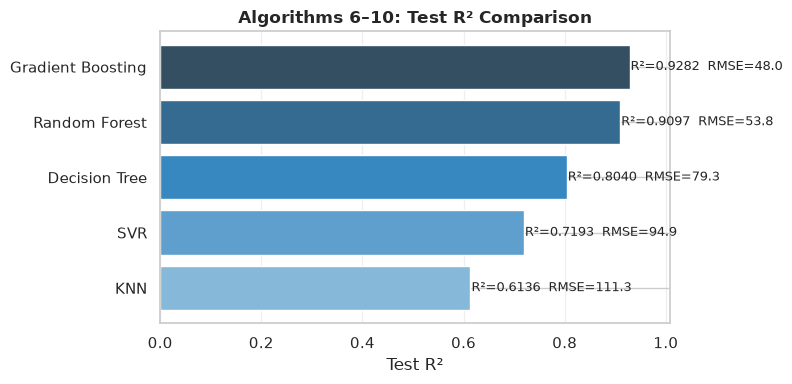

In [61]:
fig, ax = plt.subplots(figsize=(8, 4))
df_bar = df_person2.sort_values('Test R2').reset_index(drop=True)
colors_bar = sns.color_palette('Blues_d', len(df_bar))
ax.barh(df_bar['Model'], df_bar['Test R2'], color=colors_bar)
for i, (r2, rmse) in enumerate(zip(df_bar['Test R2'], df_bar['Test RMSE'])):
    ax.text(r2 + 0.002, i, f'R²={r2:.4f}  RMSE={rmse:.1f}',
            va='center', fontsize=9)
ax.set_xlabel('Test R²')
ax.set_title('Algorithms 6–10: Test R² Comparison', fontweight='bold')
ax.set_xlim(0, df_bar['Test R2'].max() + 0.08)
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

## 11. Full 10-Model Regression Comparison

To produce the complete comparison table, we re-evaluate the first five models on the same test set and combine with the results from Models 6–10.

In [62]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures

# Re-evaluate the first 5 models with same preprocessor and split
person1_models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    'Ridge (a=10)': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Ridge(alpha=10.0, random_state=RANDOM_STATE))
    ]),
    'Lasso (a=0.05)': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', Lasso(alpha=0.05, random_state=RANDOM_STATE, max_iter=10000))
    ]),
    'ElasticNet': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', ElasticNet(alpha=0.001, l1_ratio=0.9, random_state=RANDOM_STATE, max_iter=10000))
    ]),
    'Polynomial (deg=2)': Pipeline([
        ('poly_preprocessor', ColumnTransformer(
            transformers=[
                ('poly_num', Pipeline([
                    ('scaler', StandardScaler()),
                    ('poly', PolynomialFeatures(degree=2, include_bias=False))
                ]), numerical_features),
                ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features),
                ('bin', 'passthrough', binary_features)
            ],
            remainder='drop'
        )),
        ('regressor', LinearRegression())
    ]),
}

person1_results = []
for name, pipe in person1_models.items():
    metrics, _ = evaluate_regression(pipe, X_train, y_train, X_test, y_test, model_name=name)
    person1_results.append(metrics)

# Combine all 10 models
df_all = pd.DataFrame(person1_results + all_results)
df_all = df_all.sort_values('Test R2', ascending=False).reset_index(drop=True)
df_all.index += 1
df_all.index.name = 'Rank'

print("Complete 10-Model Regression Comparison (Ranked by Test R2)")
print("=" * 80)
df_all[['Model', 'Test R2', 'Test RMSE', 'Test MAE', 'Train R2']].round(4)


Complete 10-Model Regression Comparison (Ranked by Test R2)


,Model,Test R2,Test RMSE,Test MAE,Train R2
Rank,,,,,
1,Gradient Boosting,0.9282,47.9885,31.4312,0.9666
2,Random Forest,0.9097,53.8076,33.8242,0.9889
3,Decision Tree,0.8040,79.2848,48.5575,0.9358
4,Polynomial (deg=2),0.7482,89.8751,68.3780,0.7637
5,Linear Regression,0.7432,90.7581,68.7833,0.7577
6,ElasticNet,0.7432,90.7610,68.7650,0.7576
7,Lasso (a=0.05),0.7428,90.8169,68.7557,0.7572
8,Ridge (a=10),0.7425,90.8699,68.8144,0.7567
9,SVR,0.7193,94.8898,66.2254,0.7355


## 12. Top-2 Model 5-Fold Cross-Validation

As required by Section 5.D, we identify the two best-performing models from the test comparison and perform 5-fold cross-validated R² on the **training set only**.

Cross-validation tells us how stable the model's performance is across different data subsets, which is a more robust estimate of generalisation than a single train/test split. We do **not** tune on the test set.

In [63]:
from sklearn.model_selection import cross_val_score

# Get the top 2 model names
top2_names = df_all.head(2)['Model'].tolist()
print(f"Top 2 models by Test R2: {top2_names}")

# Build fresh pipelines for CV
all_model_pipelines = {**person1_models, **{
    'Decision Tree': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=best_rf_config[0], max_depth=best_rf_config[1],
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', GradientBoostingRegressor(
            n_estimators=best_gb_config[0], learning_rate=best_gb_config[1],
            max_depth=5, random_state=RANDOM_STATE
        ))
    ]),
    'SVR': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', SVR(kernel=best_svr_config[0], C=best_svr_config[1]))
    ]),
    'KNN': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1))
    ]),
}}

cv_results = []
for name in top2_names:
    pipe = all_model_pipelines[name]
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2', n_jobs=-1)
    cv_results.append({
        'Model': name,
        'CV R2 Mean': scores.mean(),
        'CV R2 Std': scores.std(),
        'CV Folds': [round(s, 4) for s in scores]
    })
    print(f"\n{name}:")
    print(f"  5-Fold CV R2: {scores.mean():.4f} +/- {scores.std():.4f}")
    print(f"  Individual folds: {[f'{s:.4f}' for s in scores]}")

df_cv = pd.DataFrame(cv_results)
df_cv[['Model', 'CV R2 Mean', 'CV R2 Std']]

Top 2 models by Test R2: ['Gradient Boosting', 'Random Forest']

Gradient Boosting:
  5-Fold CV R2: 0.9304 +/- 0.0071
  Individual folds: ['0.9201', '0.9242', '0.9377', '0.9374', '0.9325']

Random Forest:
  5-Fold CV R2: 0.9130 +/- 0.0079
  Individual folds: ['0.9035', '0.9035', '0.9170', '0.9208', '0.9204']


,Model,CV R2 Mean,CV R2 Std
0,Gradient Boosting,0.930361,0.007072
1,Random Forest,0.913033,0.007895


> **Cross-Validation Discussion:**
> - The CV R² provides a more reliable generalisation estimate than the single test split because it averages over 5 different train/validation partitions.
> - Low standard deviation across folds indicates the model's performance is stable and not heavily dependent on which specific samples end up in the validation set.
> - Note that these CV scores are computed on the training set only — the held-out test set remains untouched for final evaluation.

## 13. Regression Visualisations

### 13.1 Predicted vs Actual Plot

For the best overall model, we plot predicted values against actual values. Points close to the 45-degree line indicate accurate predictions.

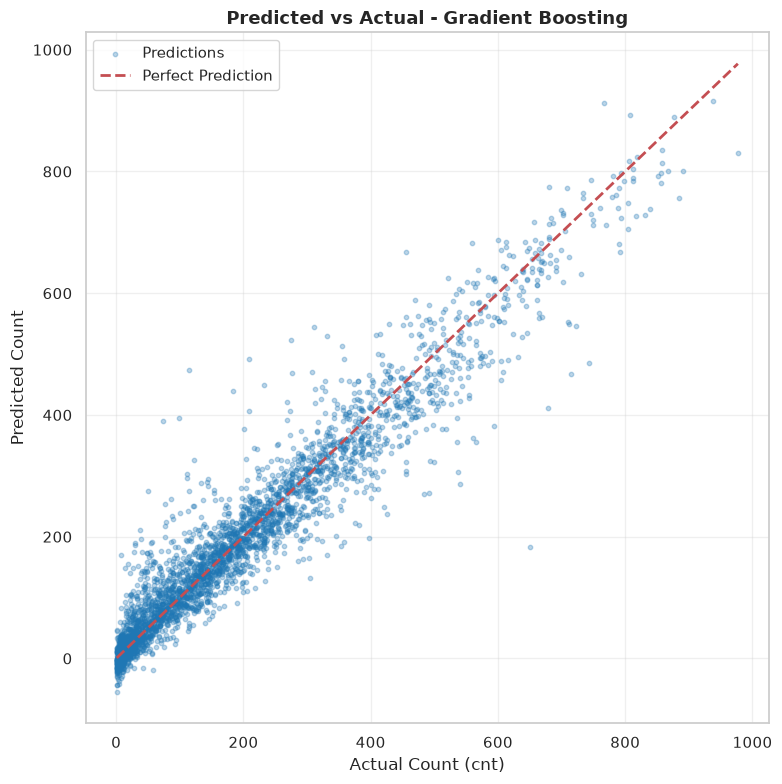

In [64]:
# Use the best model from the 10-model comparison
best_model_name = df_all.iloc[0]['Model']
best_model = all_model_pipelines[best_model_name]
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_best, alpha=0.3, s=10, color='#1f77b4', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', linewidth=2, label='Perfect Prediction')
plt.title(f'Predicted vs Actual - {best_model_name}', fontsize=13, fontweight='bold')
plt.xlabel('Actual Count (cnt)')
plt.ylabel('Predicted Count')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 13.2 Residual Plot

Residuals (actual - predicted) should ideally be randomly scattered around zero with no systematic pattern. Patterns in residuals suggest the model is missing some structure in the data.

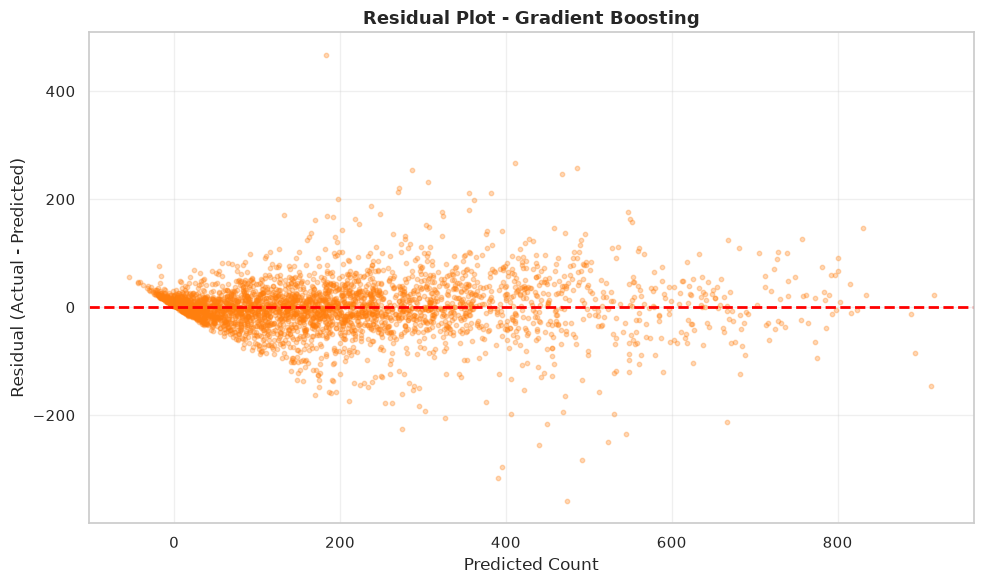

Residual statistics:
  Mean: 0.14
  Std:  47.99
  Min:  -358.35
  Max:  467.58


In [65]:
residuals = y_test.values - y_pred_best

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_best, residuals, alpha=0.3, s=10, color='#ff7f0e')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.title(f'Residual Plot - {best_model_name}', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Count')
plt.ylabel('Residual (Actual - Predicted)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Residual statistics:")
print(f"  Mean: {residuals.mean():.2f}")
print(f"  Std:  {residuals.std():.2f}")
print(f"  Min:  {residuals.min():.2f}")
print(f"  Max:  {residuals.max():.2f}")

### 13.3 Tree-Based Feature Importance

Feature importance from the best tree-based model shows which features contribute most to reducing prediction error. This is a model-specific measure (based on how much each feature reduces impurity across all trees).

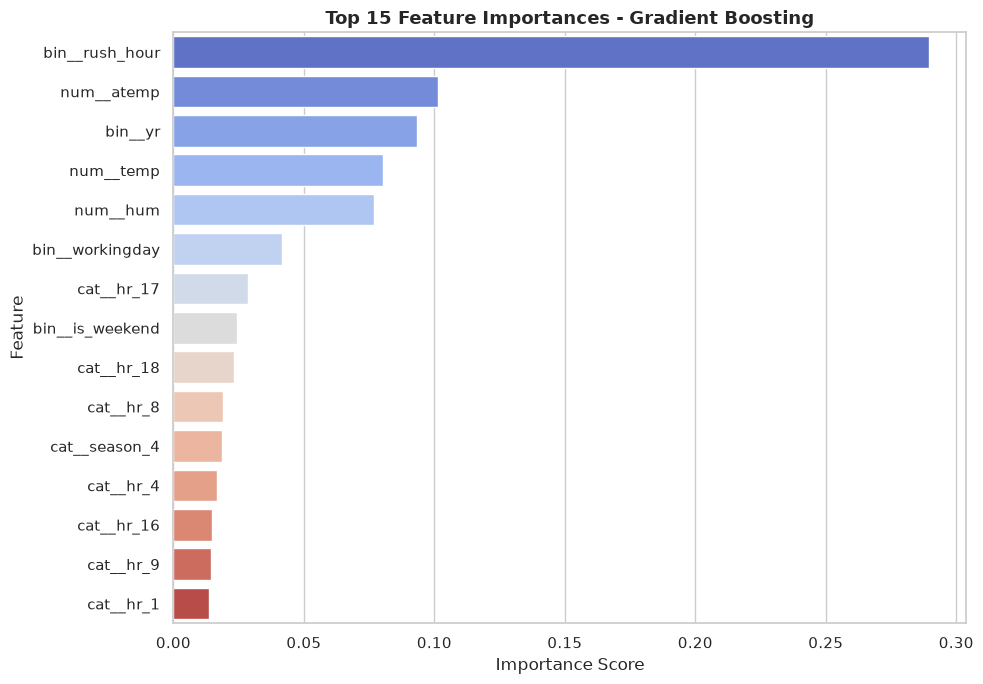


Top 5 most important features for Gradient Boosting:
  bin__rush_hour: 0.2894
  num__atemp: 0.1013
  bin__yr: 0.0933
  num__temp: 0.0805
  num__hum: 0.0769


In [66]:
# Use the best tree-based model (RF or GB, whichever ranked higher)
tree_models_ranked = df_all[df_all['Model'].isin(['Random Forest', 'Gradient Boosting', 'Decision Tree'])]
best_tree_name = tree_models_ranked.iloc[0]['Model']
best_tree_model = trained_models[best_tree_name]

importances_final = best_tree_model.named_steps['regressor'].feature_importances_
feat_imp_final = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances_final
}).sort_values('Importance', ascending=False).head(15)

plt.figure(figsize=(10, 7))
colors = sns.color_palette('coolwarm', len(feat_imp_final))
sns.barplot(data=feat_imp_final, x='Importance', y='Feature', palette=colors)
plt.title(f'Top 15 Feature Importances - {best_tree_name}', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print(f"\nTop 5 most important features for {best_tree_name}:")
for _, row in feat_imp_final.head(5).iterrows():
    print(f"  {row['Feature']}: {row['Importance']:.4f}")

> **Feature Importance Observation:**
> - Hour-related features dominate, which is consistent with the EDA showing strong diurnal demand patterns (commuter peaks on working days, midday peaks on weekends).
> - Temperature features are also highly ranked, confirming that weather directly affects cycling behaviour.
> - The engineered `rush_hour` feature likely appears in the top features, validating our hypothesis that explicit commuter-hour encoding provides predictive value beyond the raw `hr` variable.

## 14. Findings & Limitations

### Key Findings
1. **Ensemble methods dominate:** Random Forest and Gradient Boosting consistently outperform single decision trees and distance-based methods, as expected for structured tabular data with categorical interactions.
2. **SVR underperforms tree-based models:** SVR is better suited for smaller, smoother datasets. The bike rental data has complex categorical structure (hour x season x weather) that trees handle more naturally.
3. **KNN is competitive but limited:** KNN performs reasonably well thanks to proper scaling, but it lacks the interpretability and feature importance insights that tree models provide.
4. **Hour of day is the strongest predictor:** Across all tree-based models, hour-related features are the most important, which aligns with the clear commuter-hour demand patterns seen in the EDA.
5. **Hyperparameter tuning provides modest gains:** GridSearchCV improved both RF and SVR over the manual baseline, but the improvements were incremental rather than transformative — suggesting the initial manual configurations were already reasonable.

### Limitations
- Results are based on a single dataset and a single 80:20 split (mitigated partially by cross-validation for the top models)
- Hyperparameter search was not exhaustive — a RandomizedSearchCV with wider ranges might find better configurations
- We did not try more advanced methods like XGBoost or LightGBM, which could potentially improve further
- Feature engineering was minimal — additional time-series features (lagged demand, rolling averages) could help